**ติดตั้งไลบรารีที่จำเป็น**

In [1]:
import pandas as pd
import numpy as np
import csv
from IPython.display import display
from sklearn.model_selection import cross_val_score

**import DATA**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%cd "/content/drive/MyDrive/Colab Notebooks"

/content/drive/MyDrive/Colab Notebooks


In [4]:
dataset = pd.read_csv('Dataset/amazon_labelled.txt', sep='\t', header=None, quoting=csv.QUOTE_NONE)
sentences = dataset.values[:, 0]
labels = dataset.values[:, 1]

**เนื้อหาของ DATA**

In [5]:
# ====================================================================
# 📊 รายละเอียดและคุณลักษณะของชุดข้อมูล (Amazon Dataset Details & Analysis)
# ====================================================================
# 1. Amazon Dataset คืออะไร?
#    - คือชุดข้อมูลสำหรับทำ Sentiment Analysis (วิเคราะห์อารมณ์/ความรู้สึกจากข้อความ)
#    - รวบรวมมาจากความคิดเห็น/รีวิวสินค้าประเภทโทรศัพท์มือถือและอุปกรณ์เสริมบนเว็บไซต์ Amazon
#    - มีเป้าหมายเพื่อให้โมเดลแยกแยะข้อความว่าเป็นเชิงบวก (Positive) หรือเชิงลบ (Negative)
#
# 2. โครงสร้างของข้อมูล (Data Structure):
#    - รูปแบบไฟล์: Plain Text File คั่นด้วยแท็บ (\t)
#    - จำนวนข้อมูลทั้งหมด: 1,000 แถว (1,000 ข้อความรีวิว)
#    - จำนวนคอลัมน์: 2 คอลัมน์หลัก
#      * Column 0 (Sentence): ข้อความรีวิวสินค้าภาษาอังกฤษ
#      * Column 1 (Label): ป้ายกำกับอารมณ์
#        - 1 = Positive (ความรู้สึกด้านบวก / ชื่นชอบสินค้า)
#        - 0 = Negative (ความรู้สึกด้านลบ / ไม่ประทับใจสินค้า)

**ดูรายละเอียด DATA**

In [6]:
dataset.head()

,0,1
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [7]:
X = []
y = []
for i in range(len(sentences)):
    X.append(sentences[i])
    y.append(labels[i])

# ตรวจสอบข้อมูลเบื้องต้น
print("จำนวนข้อมูลข้อความ (X):", len(X))
print("จำนวนป้ายกำกับ (y):", len(y))

จำนวนข้อมูลข้อความ (X): 1000
จำนวนป้ายกำกับ (y): 1000


In [8]:
# ดูขนาดของข้อมูล (จำนวนแถว, จำนวนคอลัมน์)
print(f"ขนาดของ Dataset (Rows, Columns): {dataset.shape}")

ขนาดของ Dataset (Rows, Columns): (1000, 2)


In [9]:
# ตรวจสอบการกระจายตัวของ Class (คอลัมน์ Index 1: 0 = Negative, 1 = Positive)
print("\n=== จำนวนข้อมูลแต่ละ Class ===")
print(dataset[1].value_counts())


=== จำนวนข้อมูลแต่ละ Class ===
1
0    500
1    500
Name: count, dtype: int64


In [10]:
# ตรวจสอบข้อมูลขยะหรือค่าที่หายไป (Missing Values)
print("\n=== ตรวจสอบ ค่าว่าง (Missing Values) ===")
print(dataset.isnull().sum())


=== ตรวจสอบ ค่าว่าง (Missing Values) ===
0    0
1    0
dtype: int64


In [11]:
# คำนวณความยาวของข้อความ (จำนวนตัวอักษร และ จำนวนคำ จากคอลัมน์ Index 0)
dataset['char_length'] = dataset[0].apply(len)
dataset['word_count'] = dataset[0].apply(lambda x: len(str(x).split()))

print("\n=== ค่าสถิติต่างๆ ของข้อความใน Dataset ===")
print(dataset[['char_length', 'word_count']].describe())


=== ค่าสถิติต่างๆ ของข้อความใน Dataset ===
       char_length   word_count
count  1000.000000  1000.000000
mean     55.226000    10.246000
std      34.653482     6.687616
min      11.000000     1.000000
25%      26.000000     5.000000
50%      48.000000     9.000000
75%      77.000000    15.000000
max     149.000000    30.000000


**Data prep ; Text Cleansing & Lemmatization (ทำความสะอาดข้อความ)**

In [12]:
import nltk
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk.corpus import wordnet

In [13]:
# ดาวน์โหลดทรัพยากรของ NLTK
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

True

In [14]:
# ตั้งค่า Stopwords และระบุคำปฏิเสธ/คำเน้นอารมณ์ที่ไม่ต้องการตัดออก
stop_words = set(stopwords.words('english'))
keep_words = {
    'not', 'no', 'nor', 'neither', 'never', 'none', 'without', 'cannot', 'nothing', 'nobody', 'nowhere',
    "n't", "don't", "dont", "doesn't", "doesnt", "didn't", "didnt",
    "can't", "cant", "couldn't", "couldnt", "won't", "wont", "wouldn't", "wouldnt",
    "shouldn't", "shouldnt", "isn't", "isnt", "aren't", "arent",
    "wasn't", "wasnt", "weren't", "werent", "haven't", "havent",
    "hasn't", "hasnt", "hadn me", "hadn't", "hadnt", "mustn't", "mustnt",
    'very', 'too', 'so', 'extremely', 'really', 'more', 'most', 'less', 'least',
    'quite', 'fairly', 'pretty', 'highly', 'deeply', 'absolutely', 'completely',
    'totally', 'utterly', 'exceptionally', 'incredibly', 'super', 'awfully',
    'barely', 'hardly', 'scarcely', 'almost', 'nearly', 'slightly', 'just',
    'but', 'however', 'although', 'though', 'even', 'despite', 'in spite of',
    'instead', 'whereas', 'yet', 'nevertheless', 'nonetheless', 'otherwise',
    'if', 'unless', 'until', 'except'}
custom_stopwords = stop_words - keep_words
lemmatizer = WordNetLemmatizer()

In [15]:
from nltk.corpus import wordnet

# ฟังก์ชันแปลง NLTK POS Tag ให้เข้ากับ WordNet
def get_wordnet_pos(word):
    tag = nltk.pos_tag([word])[0][1][0].upper()
    tag_dict = {"J": wordnet.ADJ, "N": wordnet.NOUN, "V": wordnet.VERB, "R": wordnet.ADV}
    return tag_dict.get(tag, wordnet.NOUN)

In [16]:
def clean_text_advanced(text):
    text = str(text).lower()

    # 1. ลบแท็ก HTML
    text = re.sub(r'<[^>]+>', ' ', text)

    # 2. แปลงสัญลักษณ์คะแนนและอิโมจิเป็นคำอารมณ์ (แก้ไข Bug :-static)
    text = re.sub(r'10/10|9/10|8/10', ' perfect ', text)
    text = re.sub(r'1/10|2/10|0/10', ' terrible ', text)
    text = text.replace(':-)', ' smile ').replace(':)', ' smile ')
    text = text.replace(':-(', ' sad ').replace(':(', ' sad ')

    # 3. ขยายคำย่อ (Contractions)
    contractions = {
        "can't": "cannot", "won't": "will not", "n't": " not",
        "'re": " are", "'s": " is", "'d": " would",
        "'ll": " will", "'t": " not", "'ve": " have", "'m": " am"
    }
    for word, replacement in contractions.items():
        text = text.replace(word, replacement)

    # 4. ลบตัวเลขและอักขระพิเศษ (คงไว้เฉพาะอักษรภาษาอังกฤษและ !)
    text = re.sub(r'[^a-z!\s]', '', text)

    # 5. Tokenize และตัด Stopwords
    words = [w for w in text.split() if w not in custom_stopwords and len(w) > 1]

    # 6. Fast POS Tagging ทั้งประโยคแล้วทำการ Lemmatize
    pos_tags = nltk.pos_tag(words)
    cleaned_words = []

    tag_dict = {"J": wordnet.ADJ, "N": wordnet.NOUN, "V": wordnet.VERB, "R": wordnet.ADV}
    for word, tag in pos_tags:
        wn_tag = tag_dict.get(tag[0].upper(), wordnet.NOUN)
        cleaned_words.append(lemmatizer.lemmatize(word, wn_tag))

    return " ".join(cleaned_words)

In [17]:
# ดาวน์โหลดทรัพยากรสำหรับ POS Tagging ที่ยังขาดอยู่ และนำเข้า wordnet ให้เรียบร้อย
import nltk
from nltk.corpus import wordnet
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# สร้างคอลัมน์ใหม่สำหรับข้อความที่ทำความสะอาดแล้ว
dataset['cleaned_text'] = dataset[0].apply(clean_text_advanced)


In [18]:
print("=== ตัวอย่างข้อความก่อน และ หลังทำ Cleansing ===")
for i in range(3):
    print(f"\n[ตัวอย่างที่ {i+1}]")
    print("ก่อน Clean :", X[i])
    print("หลัง Clean :", dataset['cleaned_text'].iloc[i])

=== ตัวอย่างข้อความก่อน และ หลังทำ Cleansing ===

[ตัวอย่างที่ 1]
ก่อน Clean : So there is no way for me to plug it in here in the US unless I go by a converter.
หลัง Clean : so no way plug u unless go converter

[ตัวอย่างที่ 2]
ก่อน Clean : Good case, Excellent value.
หลัง Clean : good case excellent value

[ตัวอย่างที่ 3]
ก่อน Clean : Great for the jawbone.
หลัง Clean : great jawbone


**การแบ่งข้อมูล (Train/Test Split) และแปลงเป็นตัวเลข (Vectorization)ด้วย Bag of Words (BoW) และ TF-IDF**


ในขั้นตอนถัดไป เราจะทำการ แบ่งข้อมูลเป็น 80:20 (Train/Test Split) ก่อน แล้วจึงแปลงข้อความให้เป็นตัวเลขด้วย Bag of Words (BoW) และ TF-IDF

สำคัญ: การแบ่งข้อมูลก่อนแปลงเป็น Vectorizer เพื่อป้องกันปัญหา Data Leakage (ไม่ให้ข้อมูลชุด Test หลุดไปมีอิทธิพลต่อการคำนวณ TF-IDF/Vocabulary ของชุด Train)

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [20]:
# 1. ดึงข้อความที่ Cleansed แล้ว และ Label ออกมา
X_text = dataset['cleaned_text'].values
y = dataset[1].values

In [21]:
# 2. แบ่งข้อมูล Train 80% และ Test 20% (ใช้ stratify เพื่อให้สัดส่วน class 0 และ 1 เท่ากันทั้งสองชุด)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=42, stratify=y
)

print(f"จำนวนข้อมูล Train: {len(X_train_text)} ข้อความ")
print(f"จำนวนข้อมูล Test:  {len(X_test_text)} ข้อความ")

จำนวนข้อมูล Train: 800 ข้อความ
จำนวนข้อมูล Test:  200 ข้อความ


In [22]:
# 3. สร้าง Feature Representation: Bag of Words (BoW)
bow_vec = CountVectorizer(ngram_range=(1, 2), max_features=3000)
X_train_bow = bow_vec.fit_transform(X_train_text).toarray()
X_test_bow = bow_vec.transform(X_test_text).toarray()

In [23]:
# 4. สร้าง Feature Representation: TF-IDF (กำหนด N-gram 1-2 และใช้ Sublinear TF)
tfidf_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_features=3000)
X_train_tfidf = tfidf_vec.fit_transform(X_train_text).toarray()
X_test_tfidf = tfidf_vec.transform(X_test_text).toarray()

In [24]:
print("\n=== แปลงข้อมูลเป็น Vector เรียบร้อย ===")
print(f"ขนาดเมทริกซ์ X_train_bow:   {X_train_bow.shape}")
print(f"ขนาดเมทริกซ์ X_train_tfidf: {X_train_tfidf.shape}")


=== แปลงข้อมูลเป็น Vector เรียบร้อย ===
ขนาดเมทริกซ์ X_train_bow:   (800, 3000)
ขนาดเมทริกซ์ X_train_tfidf: (800, 784)


**สร้าง Word Embedding Features (Word2Vec, FastText, GloVe)**

In [25]:
!pip install gensim
import gensim.downloader as api
from gensim.models import Word2Vec, FastText

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 67.8 MB/s eta 0:00:00


In [26]:
# 1. ตัดข้อความให้เป็น List of Tokens สำหรับสร้าง Embedding
train_tokens = [doc.split() for doc in X_train_text]
test_tokens = [doc.split() for doc in X_test_text]

In [27]:
# 1. เทรนโมเดล Word2Vec และ FastText จากชุดข้อมูล Train (Vector Size = 100)
# print("กำลังเทรน Word2Vec และ FastText...")
# w2v_model = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=1, sg=1, epochs=20, seed=42)
# fasttext_model = FastText(sentences=train_tokens, vector_size=100, window=5, min_count=1, sg=1, epochs=20, seed=42)

print("กำลังโหลด Word2Vec และ FastText...")
w2v_model = api.load("word2vec-google-news-300")
fasttext_model = api.load("fasttext-wiki-news-subwords-300")

กำลังโหลด Word2Vec และ FastText...
[==================================================] 100.0% 1662.8/1662.8MB downloaded
[==================================================] 100.0% 958.5/958.4MB downloaded


In [28]:
# 3. โหลด Pre-trained GloVe (glove-wiki-gigaword-300)
print("กำลังโหลด GloVe")
try:
    glove_model = api.load("glove-wiki-gigaword-300")
    has_glove = True
except Exception as e:
    print("ไม่สามารถโหลด GloVe ได้ จะใช้เฉพาะ Word2Vec และ FastText")
    has_glove = False

กำลังโหลด GloVe
[==================================================] 100.0% 376.1/376.1MB downloaded


In [29]:
# 4. ฟังก์ชันคำนวณ TF-IDF Weighted Average Vector (เวอร์ชันแก้ไขแล้ว)
def get_tfidf_weighted_embedding(tokens_list, embedding_model, tfidf_vectorizer, is_glove=False):
    # 1. เช็กอัตโนมัติ: ถ้ามี .wv ให้ใช้ .wv ถ้าเป็น Pre-trained ให้ใช้ตัวโมเดลตรงๆ
    wv = embedding_model.wv if hasattr(embedding_model, 'wv') else embedding_model

    # 2. ดึงมิติเวกเตอร์อัตโนมัติ (รองรับทั้งขนาด 100 และ 300)
    dim = wv.vector_size

    feature_names = tfidf_vectorizer.get_feature_names_out()
    tfidf_idf = dict(zip(feature_names, tfidf_vectorizer.idf_))
    vectors = []

    for tokens in tokens_list:
        doc_vector = np.zeros(dim)
        weight_sum = 0.0
        for word in tokens:
            # 3. ใช้ตัวแปร wv ตรวจสอบและดึงเวกเตอร์คำได้ทุกโมเดล
            if word in wv:
                word_emb = wv[word]
                weight = tfidf_idf.get(word, 1.0)
                doc_vector += word_emb * weight
                weight_sum += weight

        if weight_sum > 0:
            doc_vector /= weight_sum
        vectors.append(doc_vector)

    return np.array(vectors)

In [30]:
# 5. แปลงข้อความ Train/Test ให้เป็น Embedding Vectors
X_train_w2v = get_tfidf_weighted_embedding(train_tokens, w2v_model, tfidf_vec)
X_test_w2v = get_tfidf_weighted_embedding(test_tokens, w2v_model, tfidf_vec)

X_train_ft = get_tfidf_weighted_embedding(train_tokens, fasttext_model, tfidf_vec)
X_test_ft = get_tfidf_weighted_embedding(test_tokens, fasttext_model, tfidf_vec)

if has_glove:
    X_train_glove = get_tfidf_weighted_embedding(train_tokens, glove_model, tfidf_vec, is_glove=True)
    X_test_glove = get_tfidf_weighted_embedding(test_tokens, glove_model, tfidf_vec, is_glove=True)

print("\n=== แปลงข้อมูลเป็น Word Embedding เรียบร้อย ===")
print(f"ขนาดเมทริกซ์ X_train_w2v: {X_train_w2v.shape}")
print(f"ขนาดเมทริกซ์ X_train_ft:  {X_train_ft.shape}")
if has_glove:
    print(f"ขนาดเมทริกซ์ X_train_glove: {X_train_glove.shape}")


=== แปลงข้อมูลเป็น Word Embedding เรียบร้อย ===
ขนาดเมทริกซ์ X_train_w2v: (800, 300)
ขนาดเมทริกซ์ X_train_ft:  (800, 300)
ขนาดเมทริกซ์ X_train_glove: (800, 300)


**TRAIN โมเดล**

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB,GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

In [32]:
model_forest = RandomForestClassifier()
model_svm = LinearSVC()
model_mlp = MLPClassifier()
model_lr = LogisticRegression()
model_nb = MultinomialNB()

In [33]:
# model_forest = RandomForestClassifier(n_estimators=100, random_state=42)
# model_svm = LinearSVC(C=2.0,loss='hinge', random_state=42)
# model_mlp = MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, alpha=0.01, random_state=42)
# model_lr = LogisticRegression(C=2.0, max_iter=2000, random_state=42)
# model_nb = MultinomialNB(alpha=0.3)

In [34]:
models = {
    "Random Forest": model_forest,
    "Linear SVM": model_svm,
    "ANN (MLP)": model_mlp,
    "Logistic Regression": model_lr,
    "Naive Bayes": model_nb
}

In [35]:
print("=== กำลังเริ่มเทรนโมเดลทั้ง 5 ตัว ===")
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print(f"✓ เทรนโมเดล {name} เรียบร้อยแล้ว")

=== กำลังเริ่มเทรนโมเดลทั้ง 5 ตัว ===
✓ เทรนโมเดล Random Forest เรียบร้อยแล้ว
✓ เทรนโมเดล Linear SVM เรียบร้อยแล้ว
✓ เทรนโมเดล ANN (MLP) เรียบร้อยแล้ว
✓ เทรนโมเดล Logistic Regression เรียบร้อยแล้ว
✓ เทรนโมเดล Naive Bayes เรียบร้อยแล้ว


In [36]:
feature_sets = {
    "BoW": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "Word2Vec": (X_train_w2v, X_test_w2v),
    "FastText": (X_train_ft, X_test_ft)
}
if 'X_train_glove' in globals():
    feature_sets["GloVe"] = (X_train_glove, X_test_glove)

**ผลประเมิน split 80/20**

In [37]:
def get_base_models(is_embedding=False):
    models = {
        "ANN": MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, alpha=0.01, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
        "SVM": LinearSVC(C=1.0, loss='squared_hinge', max_iter=5000, dual='auto', random_state=42),
        "Logistic Regression": LogisticRegression(C=2.0, max_iter=2000, random_state=42)
    }
    # Naive Bayes: ใช้ MultinomialNB สำหรับ BoW/TF-IDF และใช้ GaussianNB สำหรับ Word Embedding
    if is_embedding:
        models["Naive Bayes"] = GaussianNB()
    else:
        models["Naive Bayes"] = MultinomialNB(alpha=0.3)

    return models

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

eval_results = []
results_list = []  # สร้างลิสต์สำหรับเก็บวัตถุโมเดลและ X_test ไว้ใช้งานต่อ

for feat_name, (X_tr, X_te) in feature_sets.items():
    is_emb = feat_name in ["Word2Vec", "GloVe", "FastText"]
    models_dict = get_base_models(is_embedding=is_emb)

    for model_name, model in models_dict.items():
        # 1. Train โมเดล
        model.fit(X_tr, y_train)

        # 2. Predict บน Test Set (20%)
        y_pred = model.predict(X_te)

        # 3. คำนวณ Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)

        # เก็บผลลัพธ์รูปตารางสำหรับ DataFrame
        eval_results.append({
            "Feature": feat_name,
            "Model": model_name,
            "Accuracy": round(acc, 5),
            "Precision": round(prec, 6),
            "Recall": round(rec, 4),
            "F1-score": round(f1, 6)
        })

        # เก็บวัตถุโมเดลและ X_test ลงลิสต์อัตโนมัติ
        results_list.append({
            "name": f"{feat_name} + {model_name}",
            "model": model,      # ตัวโมเดลที่ fit เรียบร้อยแล้ว
            "X_test": X_te,      # X_test ที่ใช้กับ Feature นี้
            "acc": round(acc, 5),
            "f1": round(f1, 6)
        })

In [39]:
# 4. แปลงเป็น DataFrame และแสดงผลตาราง
df_comparison = pd.DataFrame(eval_results)
display(df_comparison)

,Feature,Model,Accuracy,Precision,Recall,F1-score
0,BoW,ANN,0.830,0.805556,0.87,0.836538
1,BoW,Random Forest,0.795,0.756522,0.87,0.809302
2,BoW,SVM,0.790,0.784314,0.80,0.792079
3,BoW,Logistic Regression,0.795,0.804124,0.78,0.791878
4,BoW,Naive Bayes,0.800,0.783019,0.83,0.805825
5,TF-IDF,ANN,0.805,0.779817,0.85,0.813397
6,TF-IDF,Random Forest,0.775,0.743363,0.84,0.788732
7,TF-IDF,SVM,0.800,0.806122,0.79,0.797980
8,TF-IDF,Logistic Regression,0.805,0.814433,0.79,0.802030
9,TF-IDF,Naive Bayes,0.800,0.812500,0.78,0.795918


In [40]:
df_comparison = pd.DataFrame(eval_results)

# เลือกเรียงลำดับตาม: 'F1-score' หรือ 'Accuracy' (เปลี่ยนชื่อคอลัมน์ตรงนี้ได้เลย)
sort_metric = 'Accuracy'

# เรียงจากมากไปน้อย (ascending=False) และรีเซ็ตเลข Index ใหม่
df_sorted = df_comparison.sort_values(by=sort_metric, ascending=False).reset_index(drop=True)

print(f"=== ตารางผลประเมิน (Split 80/20) เรียงตาม {sort_metric} (มากไปน้อย) ===")
display(df_sorted)

=== ตารางผลประเมิน (Split 80/20) เรียงตาม Accuracy (มากไปน้อย) ===


,Feature,Model,Accuracy,Precision,Recall,F1-score
0,BoW,ANN,0.830,0.805556,0.87,0.836538
1,FastText,ANN,0.830,0.817308,0.85,0.833333
2,TF-IDF,Logistic Regression,0.805,0.814433,0.79,0.802030
3,TF-IDF,ANN,0.805,0.779817,0.85,0.813397
4,BoW,Naive Bayes,0.800,0.783019,0.83,0.805825
5,TF-IDF,Naive Bayes,0.800,0.812500,0.78,0.795918
6,TF-IDF,SVM,0.800,0.806122,0.79,0.797980
7,BoW,Random Forest,0.795,0.756522,0.87,0.809302
8,BoW,Logistic Regression,0.795,0.804124,0.78,0.791878
9,Word2Vec,ANN,0.790,0.790000,0.79,0.790000


**กราฟของ SPLIT 80/20**

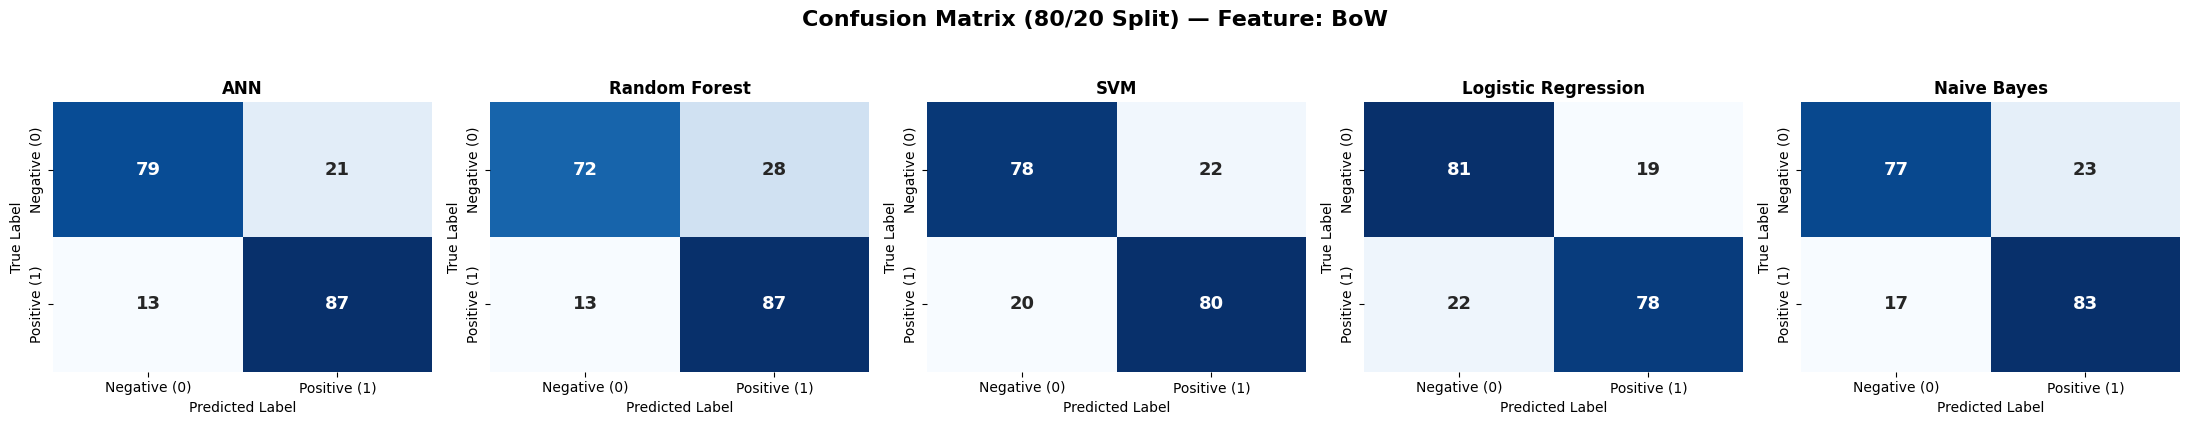

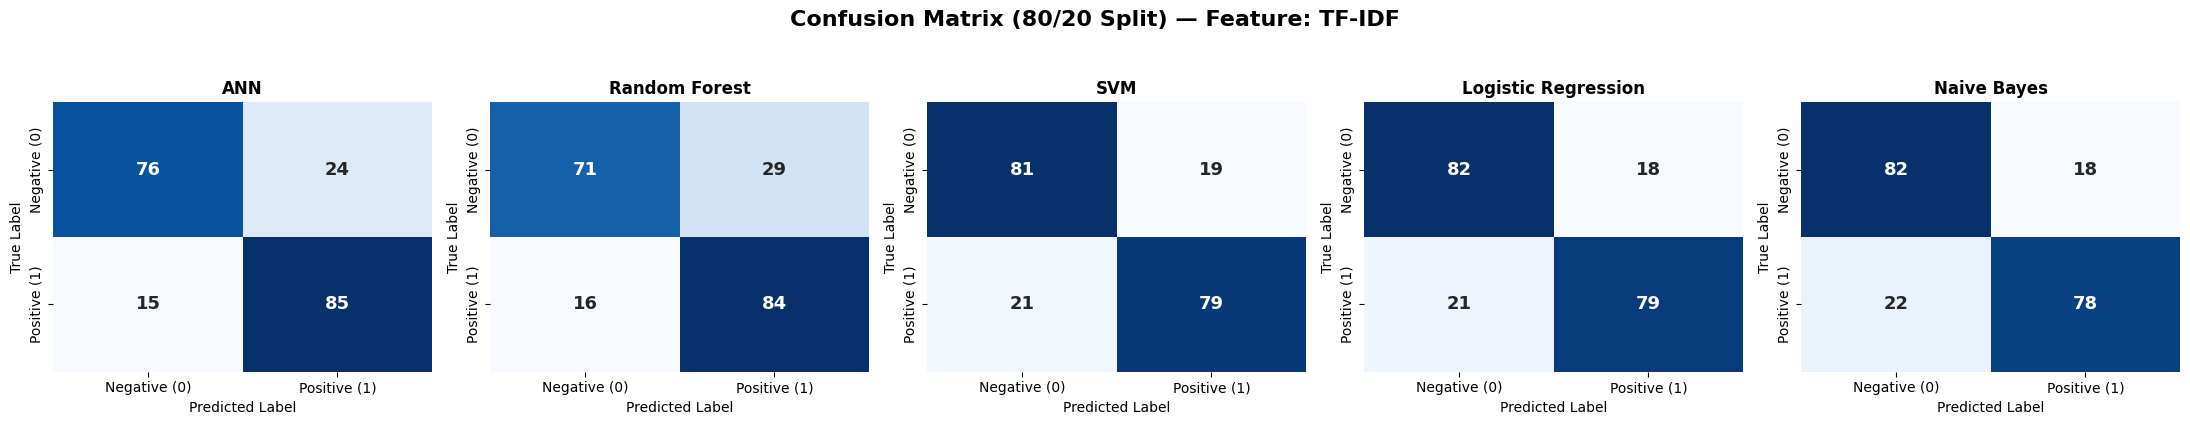

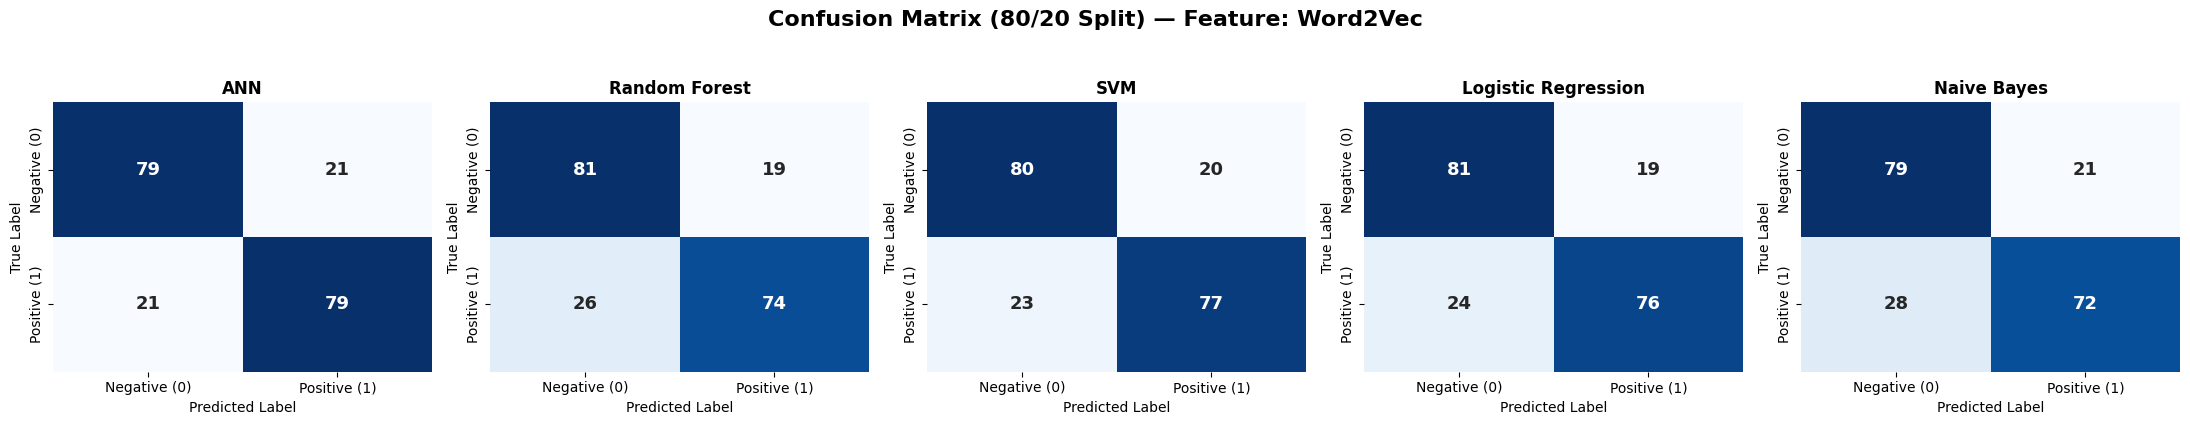

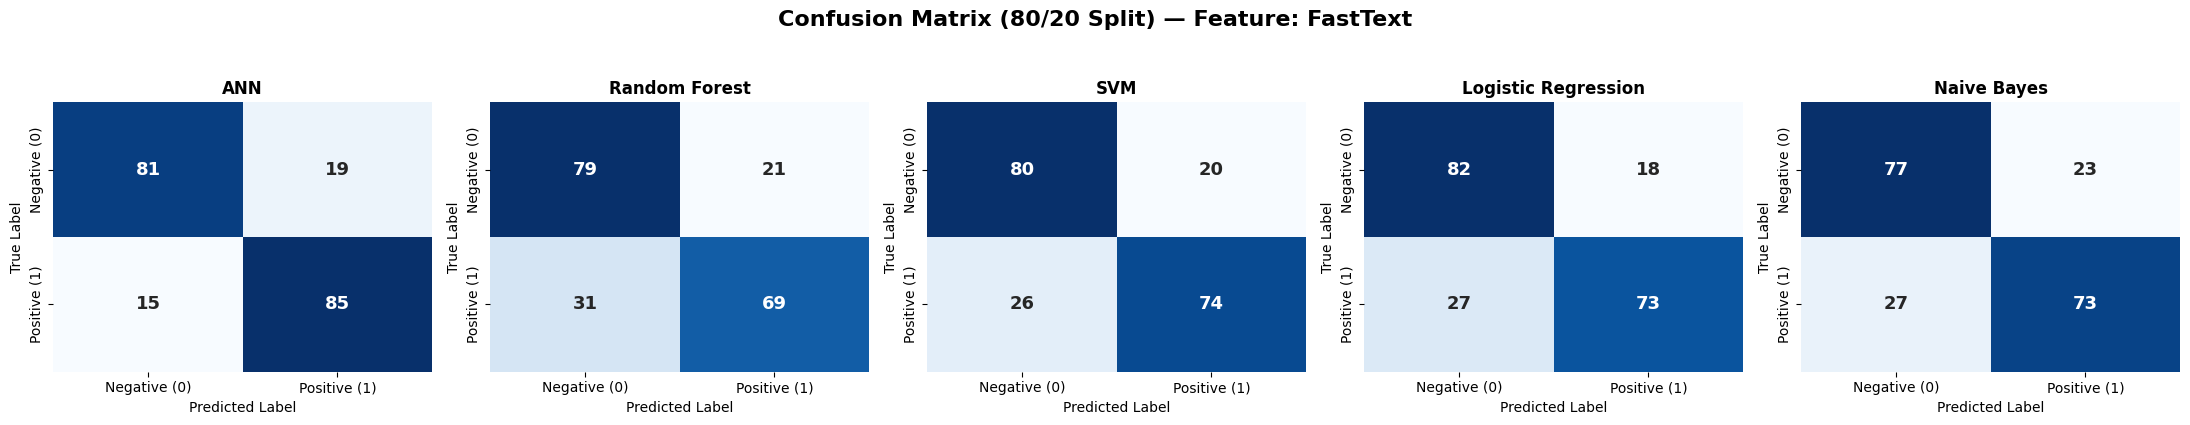

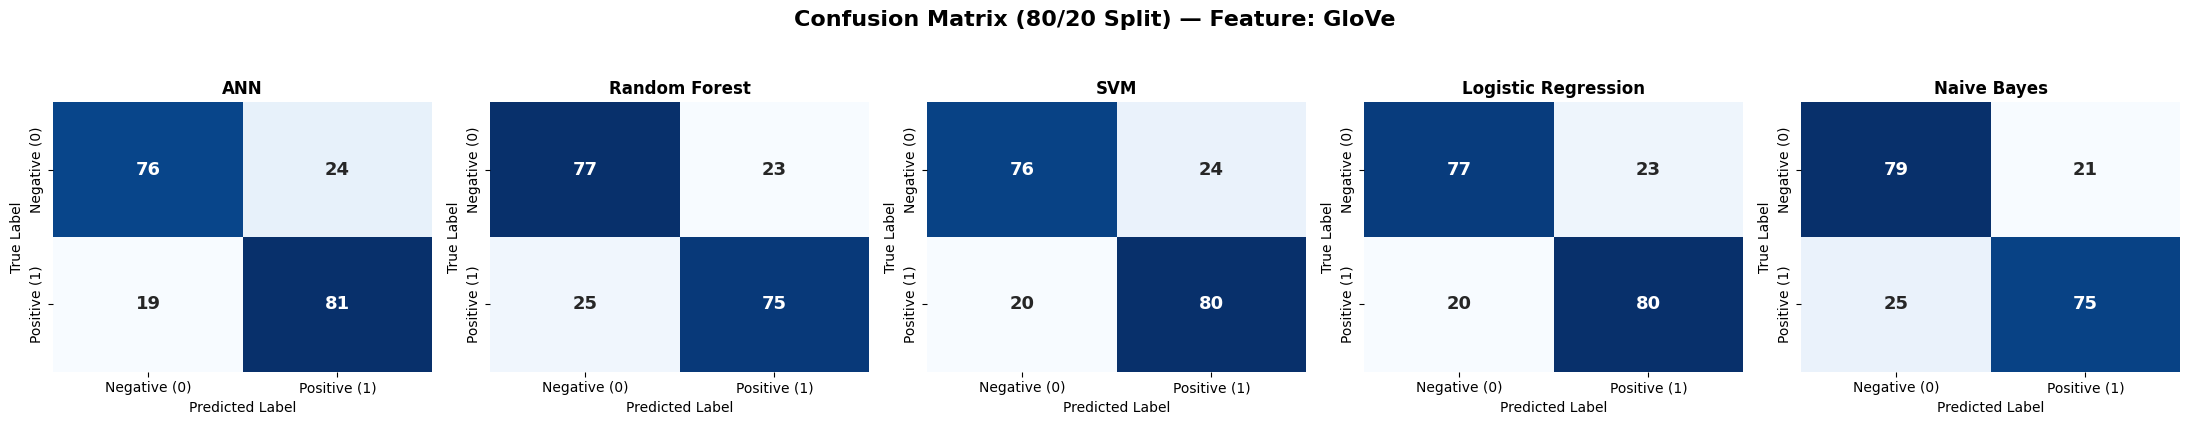

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# วนลูปสร้าง Confusion Matrix สำหรับทุก Feature Set (BoW, TF-IDF, Word2Vec, FastText, GloVe)
for feat_name, (X_tr, X_te) in feature_sets.items():
    is_emb = feat_name in ["Word2Vec", "GloVe", "FastText"]
    models_dict = get_base_models(is_embedding=is_emb)

    # สร้าง Canvas สำหรับ 5 โมเดลใน Feature นั้นๆ (1 แถว 5 คอลัมน์)
    fig, axes = plt.subplots(1, 5, figsize=(22, 4))
    fig.suptitle(f'Confusion Matrix (80/20 Split) — Feature: {feat_name}', fontsize=16, fontweight='bold', y=1.05)

    for i, (model_name, model) in enumerate(models_dict.items()):
        # Train โมเดลและ Predict บน Test Set
        model.fit(X_tr, y_train)
        y_pred = model.predict(X_te)

        # คำนวณ Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)

        # วาด Heatmap
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                    xticklabels=['Negative (0)', 'Positive (1)'],
                    yticklabels=['Negative (0)', 'Positive (1)'],
                    annot_kws={"size": 13, "weight": "bold"})

        axes[i].set_title(model_name, fontsize=12, fontweight='bold')
        axes[i].set_xlabel('Predicted Label', fontsize=10)
        axes[i].set_ylabel('True Label', fontsize=10)

    plt.tight_layout()
    plt.show()
    print("\n" + "="*120 + "\n")



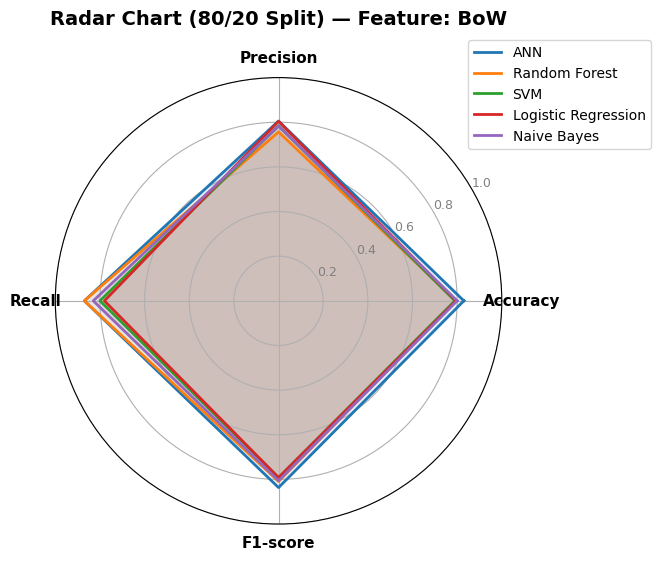

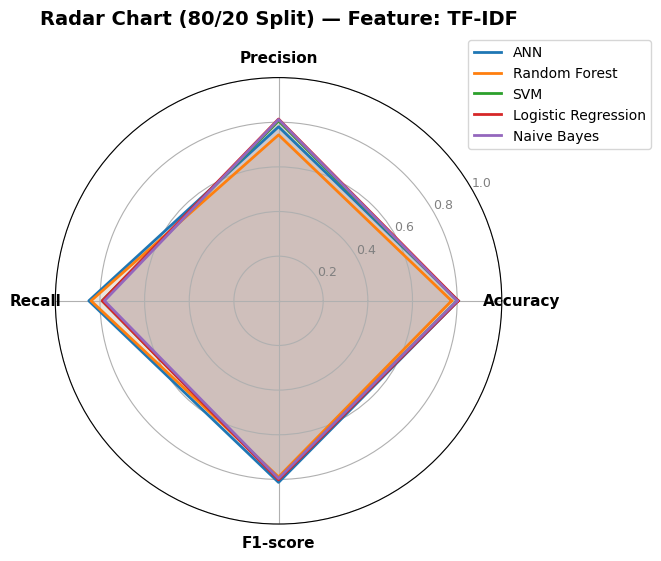

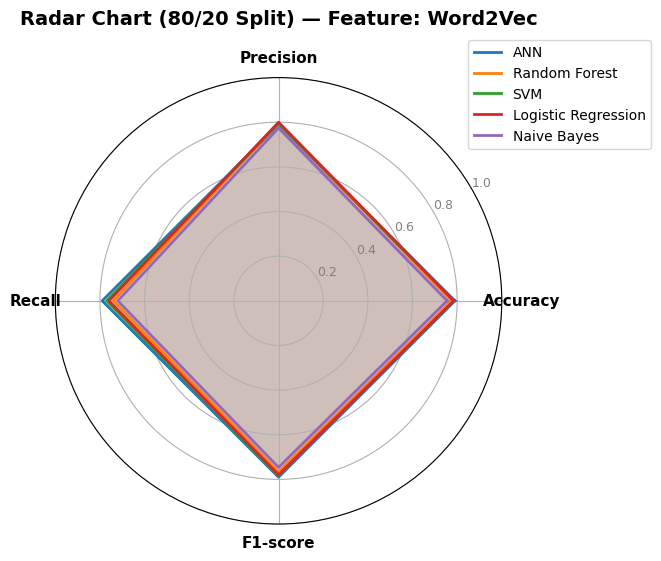

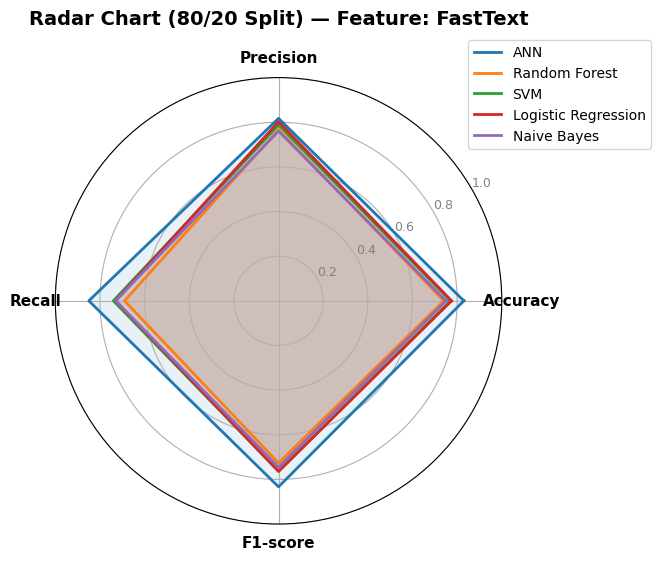

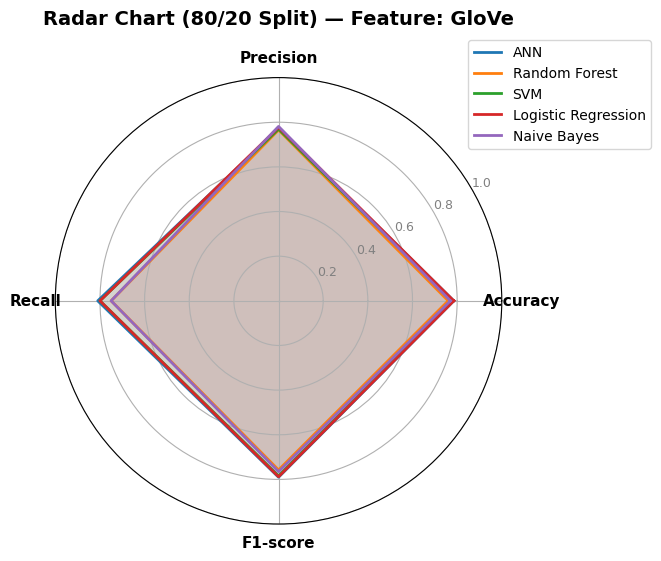

In [42]:
def plot_radar_chart(df, feature_name, metrics=['Accuracy', 'Precision', 'Recall', 'F1-score']):
    # ดึงข้อมูลเฉพาะ Feature ที่เลือก
    df_filtered = df[df['Feature'] == feature_name].copy()

    if df_filtered.empty:
        return

    categories = metrics
    N = len(categories)

    # คำนวณมุมองศา (เติมเครื่องหมาย * ที่ 2 * np.pi)
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1] # ปิดลูปวงกลม

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

    for idx, row in df_filtered.iterrows():
        values = [row[m] for m in metrics]
        values += values[:1]
        ax.plot(angles, values, linewidth=2, label=row['Model'])
        ax.fill(angles, values, alpha=0.1)

    plt.xticks(angles[:-1], categories, size=11, fontweight='bold')
    ax.set_rlabel_position(30)

    # ปรับสเกลแกน Y ให้ครอบคลุมช่วง 0.0 - 1.0 สำหรับทุก Feature
    plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2", "0.4", "0.6", "0.8", "1.0"], color="grey", size=9)
    plt.ylim(0.0, 1.0)

    plt.title(f'Radar Chart (80/20 Split) — Feature: {feature_name}', size=14, fontweight='bold', y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
    plt.tight_layout()
    plt.show()

# วนลูปแสดงกราฟเรดาร์ครบทุก Feature ที่มีอยู่ใน df_comparison
for feat in df_comparison['Feature'].unique():
    plot_radar_chart(df_comparison, feat)

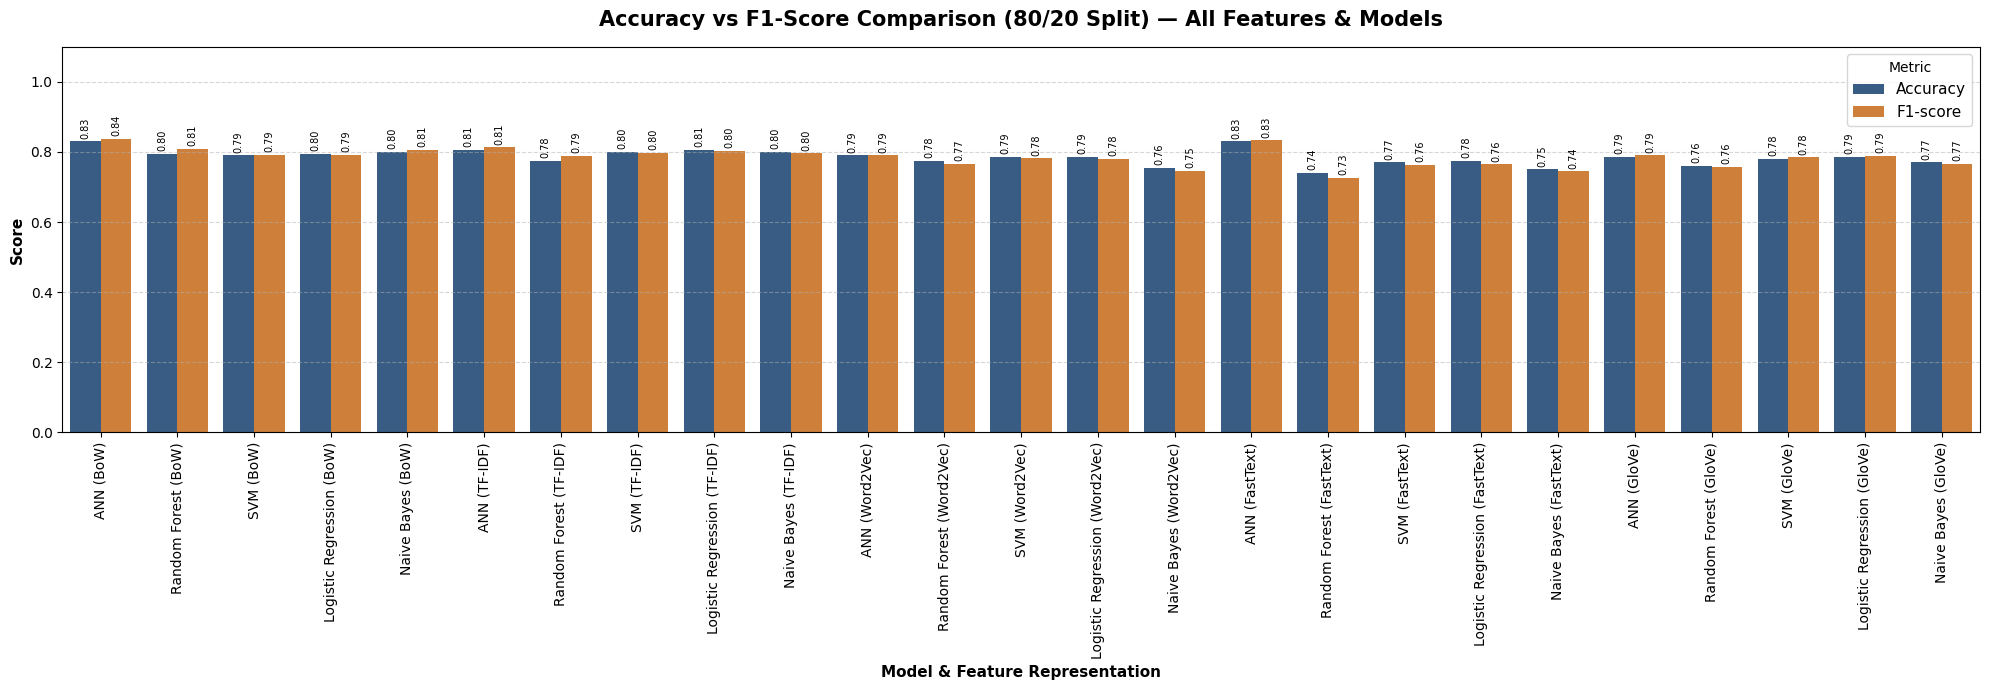

In [43]:
# 1. Transformed ข้อมูลด้วย melt เพื่อนำ Accuracy และ F1-score มาเป็น Hue
df_melt_split = pd.melt(
    df_comparison,
    id_vars=['Feature', 'Model'],
    value_vars=['Accuracy', 'F1-score'],
    var_name='Metric',
    value_name='Score'
)
df_melt_split['Model_Feature'] = df_melt_split['Model'] + " (" + df_melt_split['Feature'] + ")"

plt.figure(figsize=(20, 7))

# สร้าง Bar Plot เปรียบเทียบ Accuracy คู่กับ F1-Score
ax = sns.barplot(
    data=df_melt_split,
    x='Model_Feature',
    y='Score',
    hue='Metric',
    palette=['#2b5c8f', '#e67e22'] # สีน้ำเงิน = Accuracy, สีส้ม = F1-Score
)

plt.title('Accuracy vs F1-Score Comparison (80/20 Split) — All Features & Models', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Model & Feature Representation', fontsize=11, fontweight='bold')
plt.ylabel('Score', fontsize=11, fontweight='bold')
plt.xticks(rotation=90, fontsize=10)
plt.ylim(0.0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Metric', fontsize=11, loc='upper right')

# ตัวเลขระบุค่าบนยอดแต่ละแท่ง
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f'{height:.2f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=7, color='black',
                    xytext=(0, 2), textcoords='offset points', rotation=90)

plt.tight_layout()
plt.show()

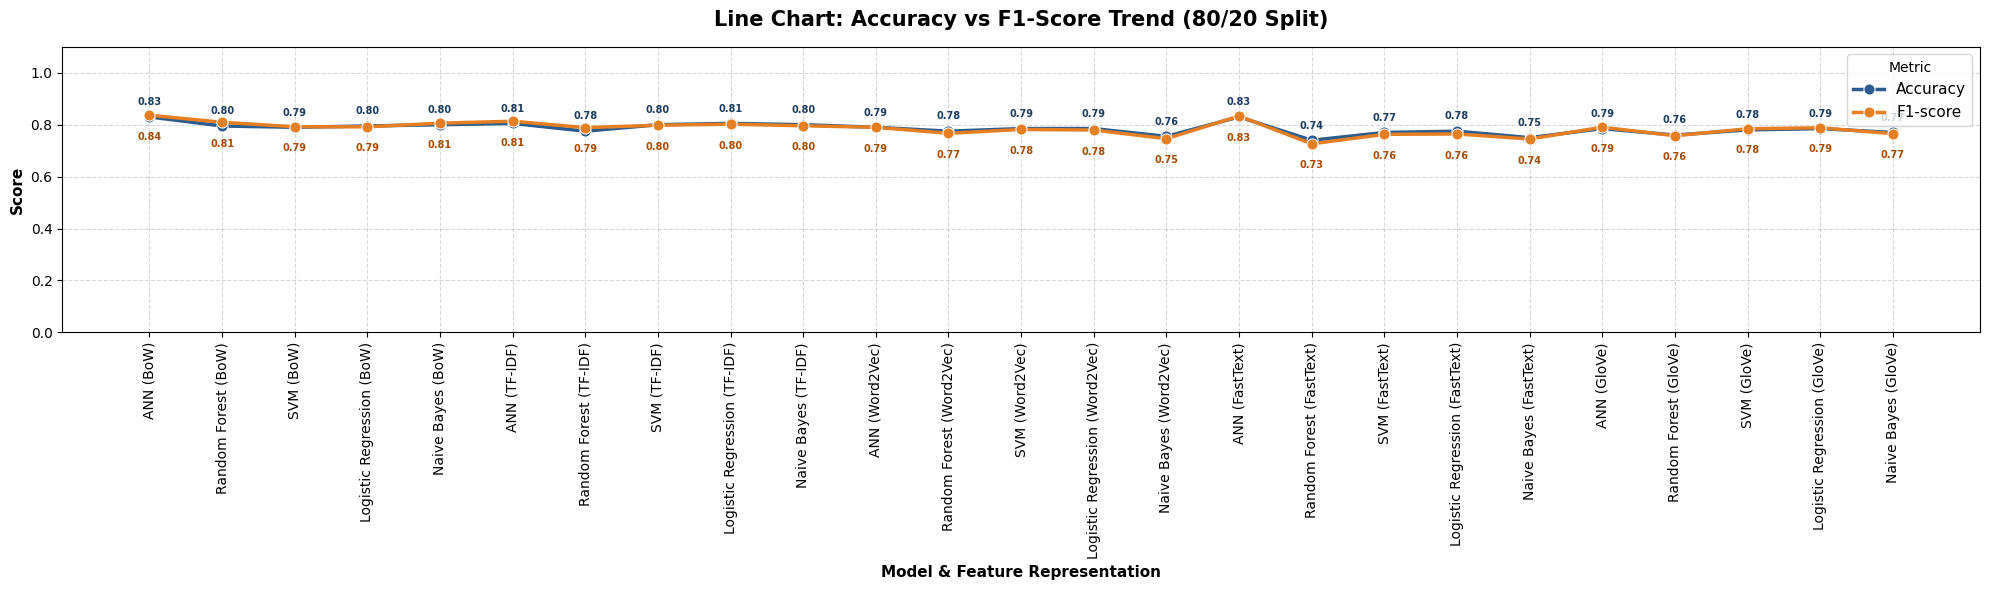

In [44]:
# --- วาดกราฟเส้น ---
plt.figure(figsize=(20, 6))
ax_line = sns.lineplot(
    data=df_melt_split,
    x='Model_Feature',
    y='Score',
    hue='Metric',
    palette=['#2b5c8f', '#e67e22'],  # สีน้ำเงิน = Accuracy, สีส้ม = F1-Score
    marker='o',
    markersize=8,
    linewidth=2.5,
)

# เติมตัวเลขบนหัวจุด (กำกับค่า Score)
for i in range(len(df_melt_split)):
    row = df_melt_split.iloc[i]
    x_val = row['Model_Feature']
    y_val = row['Score']
    metric = row['Metric']

    # Accuracy แสดงไว้ด้านบนจุด, F1-score แสดงไว้ด้านล่างจุด ป้องกันเลขซ้อนทับกัน
    if metric == 'Accuracy':
        y_offset = 7
        va = 'bottom'
        text_color = '#1b3b5f'  # สีน้ำเงินเข้ม
    else:
        y_offset = -12
        va = 'top'
        text_color = '#a84c00'  # สีส้มเข้ม

    ax_line.annotate(
        f'{y_val:.2f}',
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, y_offset),
        ha='center',
        va=va,
        fontsize=7,
        fontweight='bold',
        color=text_color
    )

plt.title(
    'Line Chart: Accuracy vs F1-Score Trend (80/20 Split)',
    fontsize=15,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Model & Feature Representation', fontsize=11, fontweight='bold')
plt.ylabel('Score', fontsize=11, fontweight='bold')
plt.xticks(rotation=90, fontsize=10)
plt.ylim(0.0, 1.1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Metric', fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

**ผลประเมิน Cross cv5**

In [45]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [46]:
# 1. ตั้งค่า 5-Fold Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
cv_results_list = []  # สร้างลิสต์สำหรับเก็บข้อมูลโมเดลและค่า CV อัตโนมัติ

In [47]:
# 2. วนลูปประเมินผล 5-Fold CV สำหรับทุก Feature และทุก Model
for feat_name, (X_tr, X_te) in feature_sets.items():
    is_emb = feat_name in ["Word2Vec", "GloVe", "FastText"]
    models_dict = get_base_models(is_embedding=is_emb)

    for model_name, model in models_dict.items():
        # คำนวณ Cross Validation บน X_tr (X_train)
        cv_scores = cross_validate(
            model, X_tr, y_train, cv=skf,
            scoring=['accuracy', 'precision', 'recall', 'f1'],
            return_estimator=True,  # เพิ่มเพื่อให้ส่งคืนโมเดลที่ fit ในแต่ละ Fold กลับมาด้วย
            n_jobs=-1
        )

        # คำนวณค่าเฉลี่ย
        mean_acc = round(np.mean(cv_scores['test_accuracy']), 5)
        mean_prec = round(np.mean(cv_scores['test_precision']), 6)
        mean_rec = round(np.mean(cv_scores['test_recall']), 4)
        mean_f1 = round(np.mean(cv_scores['test_f1']), 6)

        # 1. เก็บผลลัพธ์สำหรับแสดงใน DataFrame
        cv_results.append({
            "Feature": feat_name,
            "Model": model_name,
            "CV Accuracy": mean_acc,
            "CV Precision": mean_prec,
            "CV Recall": mean_rec,
            "CV F1-score": mean_f1
        })

        # 2. เก็บวัตถุโมเดลและรายละเอียดผลลัพธ์ลงลิสต์อัตโนมัติ
        cv_results_list.append({
            "name": f"{feat_name} + {model_name}",
            "feature": feat_name,
            "model_name": model_name,
            "estimators": cv_scores['estimator'],  # โมเดลทั้ง 5 ตัวที่ผ่านการเทรนในแต่ละ Fold
            "cv_acc": mean_acc,
            "cv_f1": mean_f1,
            "raw_scores": cv_scores  # คะแนนดิบทุก Fold เผื่อใช้ดูค่า Std Dev
        })

In [48]:
# 3. แปลงเป็น DataFrame และแสดงผลตาราง
df_cv_comparison = pd.DataFrame(cv_results)
display(df_cv_comparison)

,Feature,Model,CV Accuracy,CV Precision,CV Recall,CV F1-score
0,BoW,ANN,0.83125,0.811155,0.8650,0.836607
1,BoW,Random Forest,0.81125,0.788663,0.8600,0.820548
2,BoW,SVM,0.82625,0.813567,0.8475,0.829746
3,BoW,Logistic Regression,0.82250,0.832412,0.8100,0.820388
4,BoW,Naive Bayes,0.81000,0.788901,0.8475,0.816426
5,TF-IDF,ANN,0.83250,0.824461,0.8500,0.835240
6,TF-IDF,Random Forest,0.80000,0.772076,0.8550,0.810452
7,TF-IDF,SVM,0.83875,0.844211,0.8325,0.837633
8,TF-IDF,Logistic Regression,0.83000,0.853720,0.7975,0.824026
9,TF-IDF,Naive Bayes,0.82375,0.820598,0.8300,0.824269


In [49]:
df_cv_comparison = pd.DataFrame(cv_results)

# เลือกเรียงตาม: 'CV F1-score' หรือ 'CV Accuracy'
sort_cv_metric = 'CV Accuracy'

df_cv_sorted = df_cv_comparison.sort_values(by=sort_cv_metric, ascending=False).reset_index(drop=True)

print(f"=== ตารางผลประเมิน (5-Fold CV) เรียงตาม {sort_cv_metric} (มากไปน้อย) ===")
display(df_cv_sorted)

=== ตารางผลประเมิน (5-Fold CV) เรียงตาม CV Accuracy (มากไปน้อย) ===


,Feature,Model,CV Accuracy,CV Precision,CV Recall,CV F1-score
0,FastText,SVM,0.84875,0.850916,0.8450,0.847590
1,TF-IDF,SVM,0.83875,0.844211,0.8325,0.837633
2,TF-IDF,ANN,0.83250,0.824461,0.8500,0.835240
3,FastText,Logistic Regression,0.83125,0.847709,0.8075,0.826587
4,BoW,ANN,0.83125,0.811155,0.8650,0.836607
5,TF-IDF,Logistic Regression,0.83000,0.853720,0.7975,0.824026
6,Word2Vec,Logistic Regression,0.83000,0.834905,0.8225,0.828450
7,Word2Vec,SVM,0.82750,0.825912,0.8300,0.827892
8,BoW,SVM,0.82625,0.813567,0.8475,0.829746
9,TF-IDF,Naive Bayes,0.82375,0.820598,0.8300,0.824269


**กราฟ Cross CV-5**

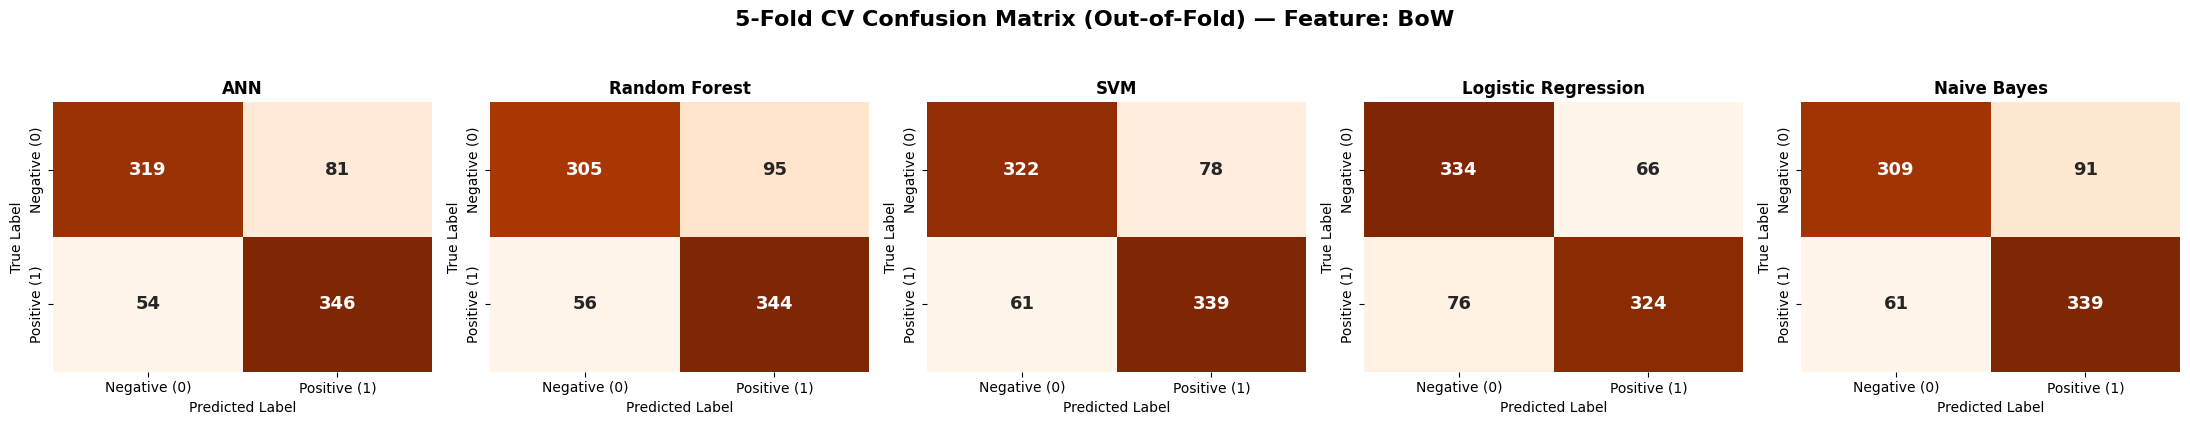

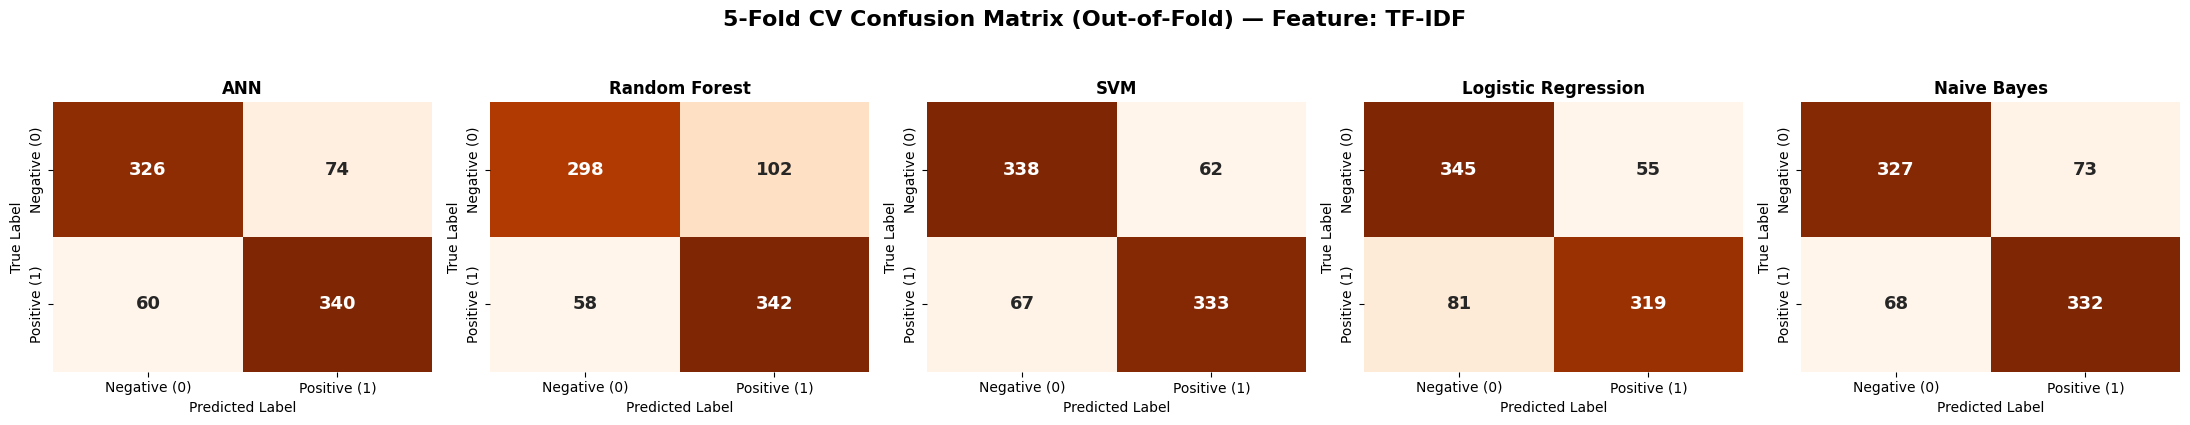

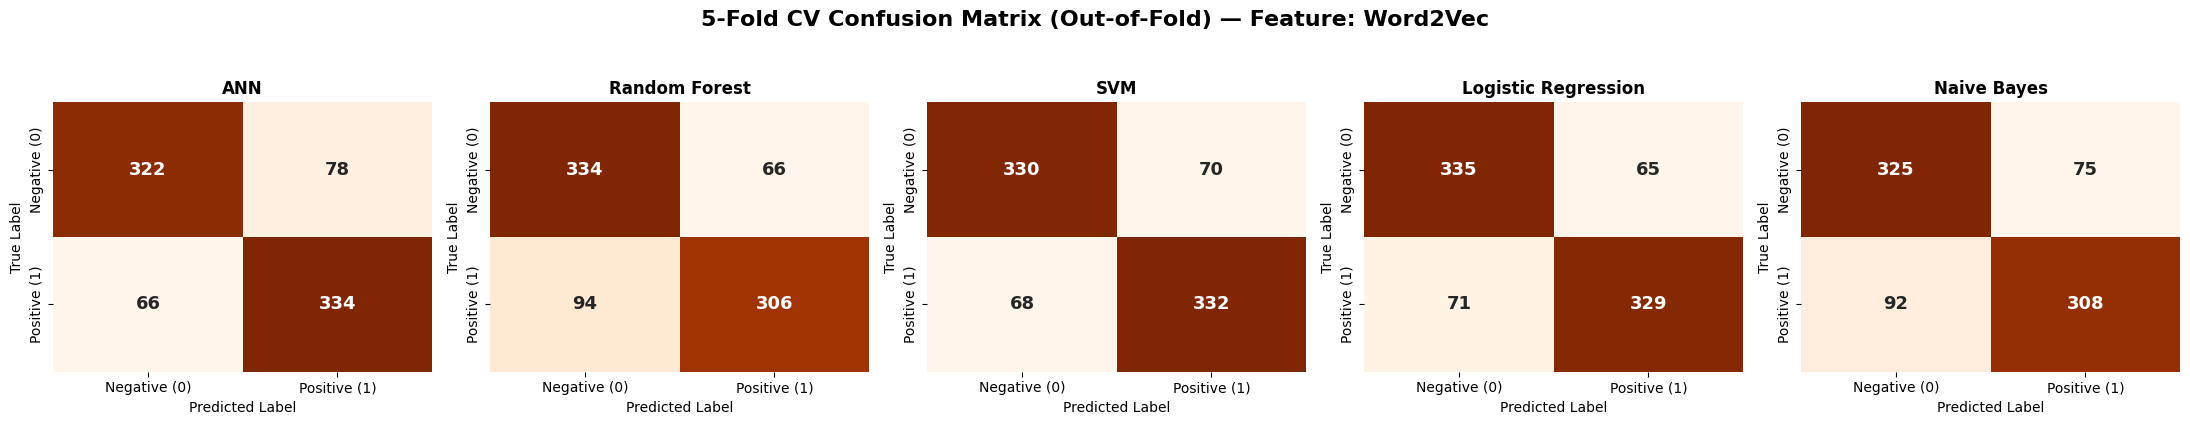

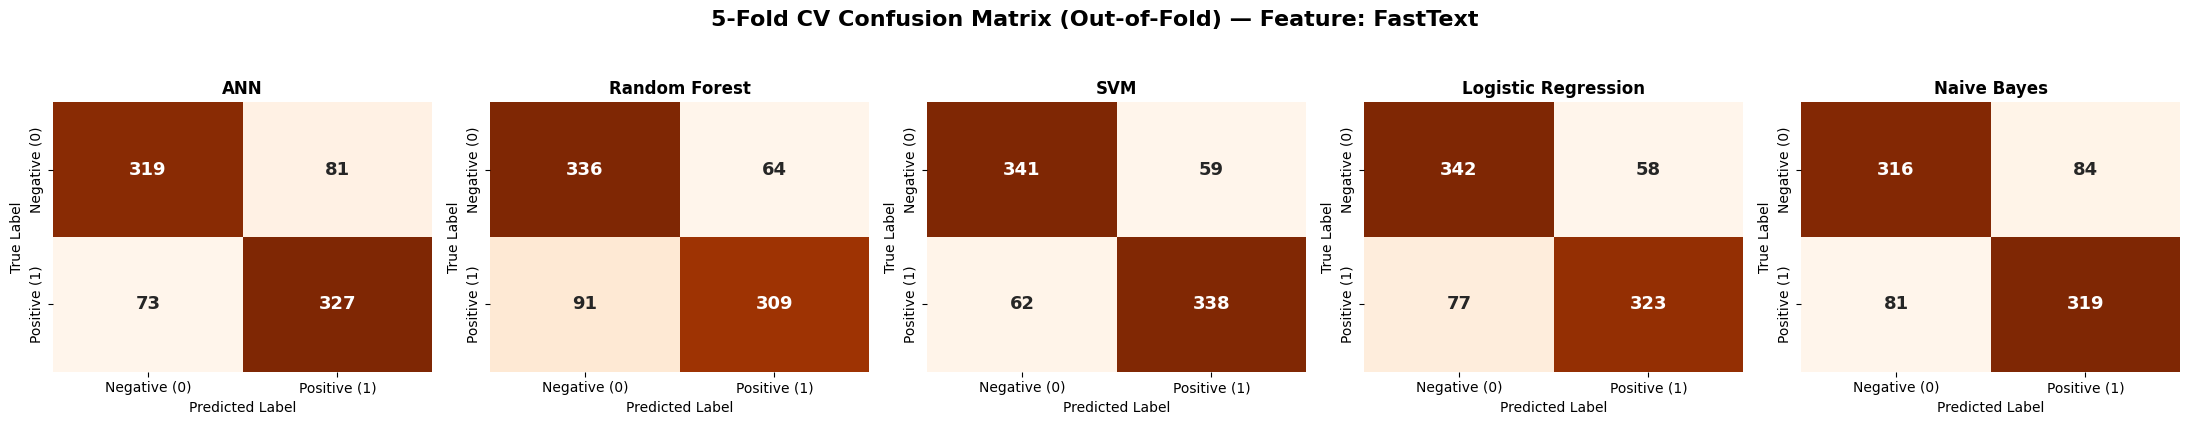

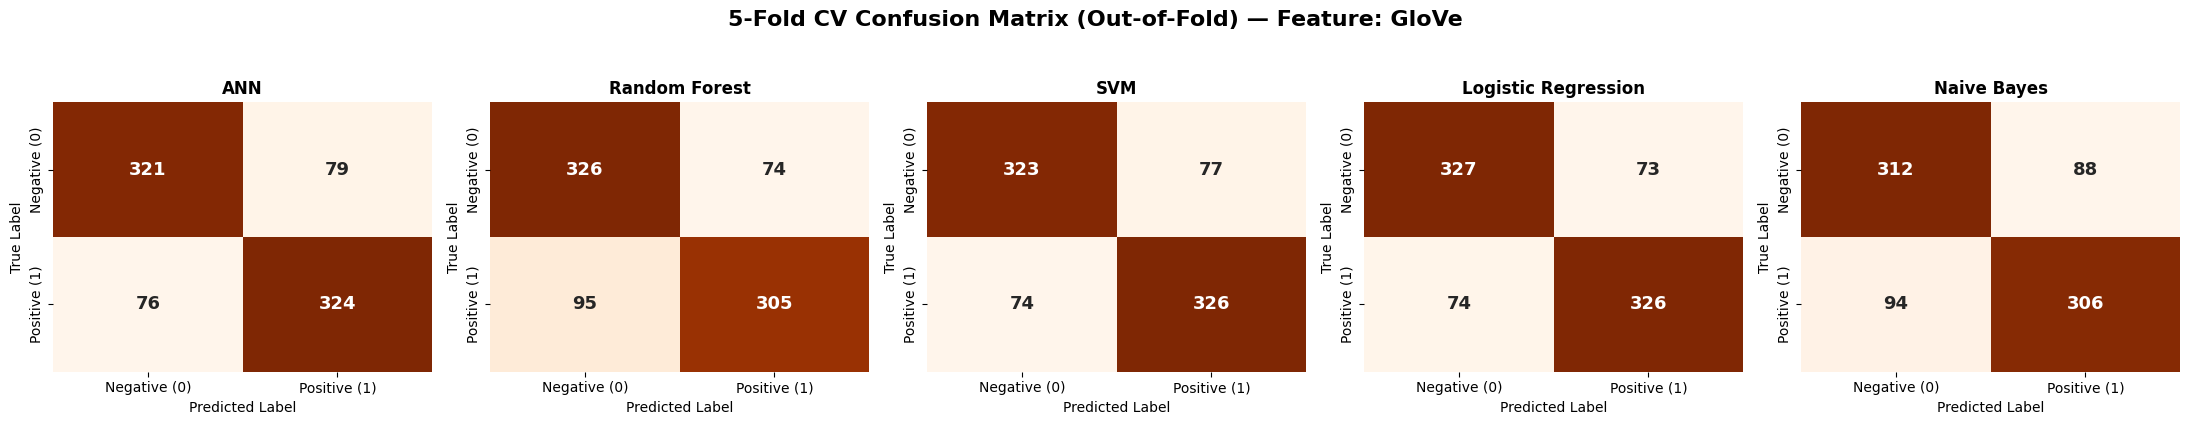

In [50]:
from sklearn.model_selection import cross_val_predict
# วนลูปสร้าง Confusion Matrix สำหรับ 5-Fold CV ครบทุก Feature
for feat_name, (X_tr, X_te) in feature_sets.items():
    is_emb = feat_name in ["Word2Vec", "GloVe", "FastText"]
    models_dict = get_base_models(is_embedding=is_emb)

    # สร้าง Canvas สำหรับ 5 โมเดลใน Feature นั้นๆ (1 แถว 5 คอลัมน์)
    fig, axes = plt.subplots(1, 5, figsize=(22, 4))
    fig.suptitle(f'5-Fold CV Confusion Matrix (Out-of-Fold) — Feature: {feat_name}', fontsize=16, fontweight='bold', y=1.05)

    for i, (model_name, model) in enumerate(models_dict.items()):
        # ดึงผลทำนาย Out-of-Fold จากทั้ง 5 Folds บนข้อมูล Train (800 ข้อมูล)
        y_pred_cv = cross_val_predict(model, X_tr, y_train, cv=skf, n_jobs=-1)

        # คำนวณ Confusion Matrix รวมจากทั้ง 5 Folds
        cm = confusion_matrix(y_train, y_pred_cv)

        # วาด Heatmap (ใช้โทนสี Oranges เพื่อแยกจากชุด 80/20)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[i], cbar=False,
                    xticklabels=['Negative (0)', 'Positive (1)'],
                    yticklabels=['Negative (0)', 'Positive (1)'],
                    annot_kws={"size": 13, "weight": "bold"})

        axes[i].set_title(model_name, fontsize=12, fontweight='bold')
        axes[i].set_xlabel('Predicted Label', fontsize=10)
        axes[i].set_ylabel('True Label', fontsize=10)

    plt.tight_layout()
    plt.show()
    print("\n" + "="*120 + "\n")

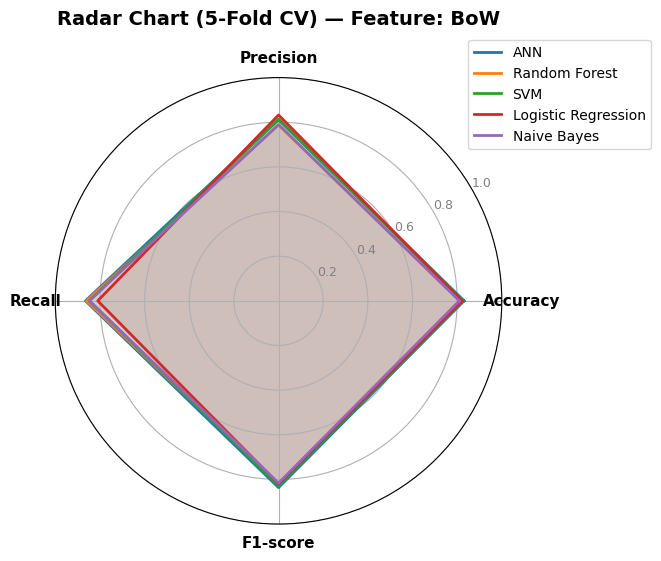

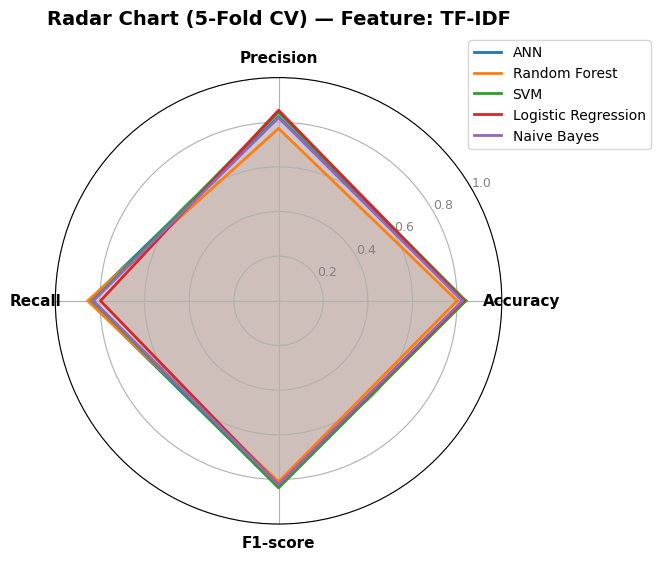

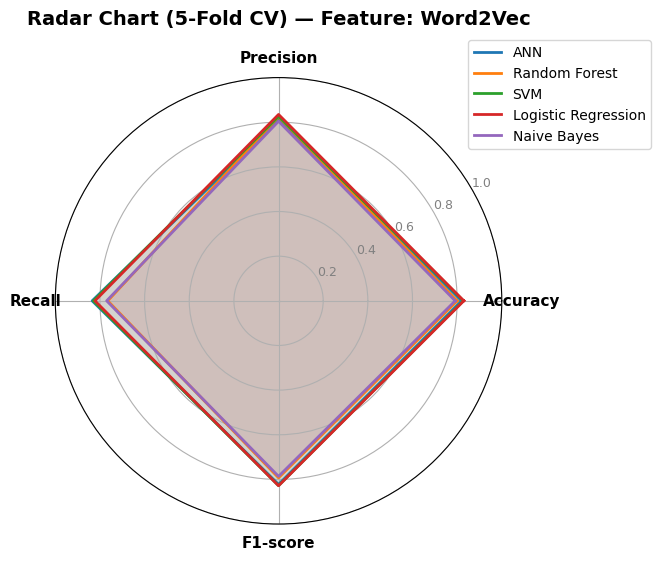

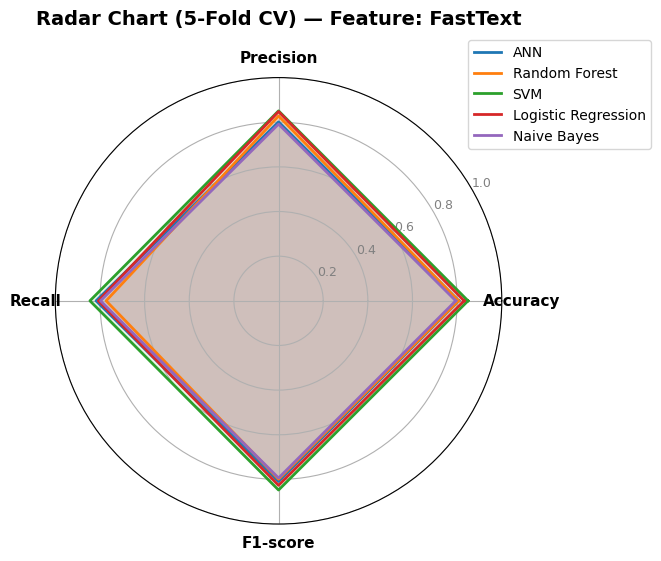

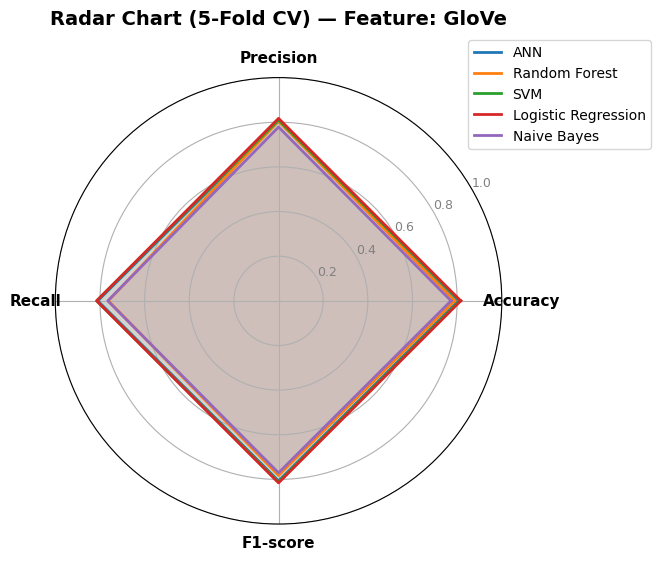

In [51]:
def plot_radar_chart_cv(df, feature_name, metrics=['CV Accuracy', 'CV Precision', 'CV Recall', 'CV F1-score']):
    # ดึงข้อมูลเฉพาะ Feature ที่เลือก
    df_filtered = df[df['Feature'] == feature_name].copy()

    if df_filtered.empty:
        return

    categories = ['Accuracy', 'Precision', 'Recall', 'F1-score'] # ชื่อแกนแสดงผล
    N = len(categories)

    # คำนวณมุมองศา
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1] # ปิดลูปวงกลม

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

    for idx, row in df_filtered.iterrows():
        values = [row[m] for m in metrics]
        values += values[:1]
        ax.plot(angles, values, linewidth=2, label=row['Model'])
        ax.fill(angles, values, alpha=0.1)

    plt.xticks(angles[:-1], categories, size=11, fontweight='bold')
    ax.set_rlabel_position(30)

    # ปรับสเกลแกน Y ให้ครอบคลุม 0.0 - 1.0
    plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2", "0.4", "0.6", "0.8", "1.0"], color="grey", size=9)
    plt.ylim(0.0, 1.0)

    plt.title(f'Radar Chart (5-Fold CV) — Feature: {feature_name}', size=14, fontweight='bold', y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
    plt.tight_layout()
    plt.show()

# วนลูปแสดงกราฟเรดาร์สำหรับ 5-Fold CV ครบทุก Feature
for feat in df_cv_comparison['Feature'].unique():
    plot_radar_chart_cv(df_cv_comparison, feat)

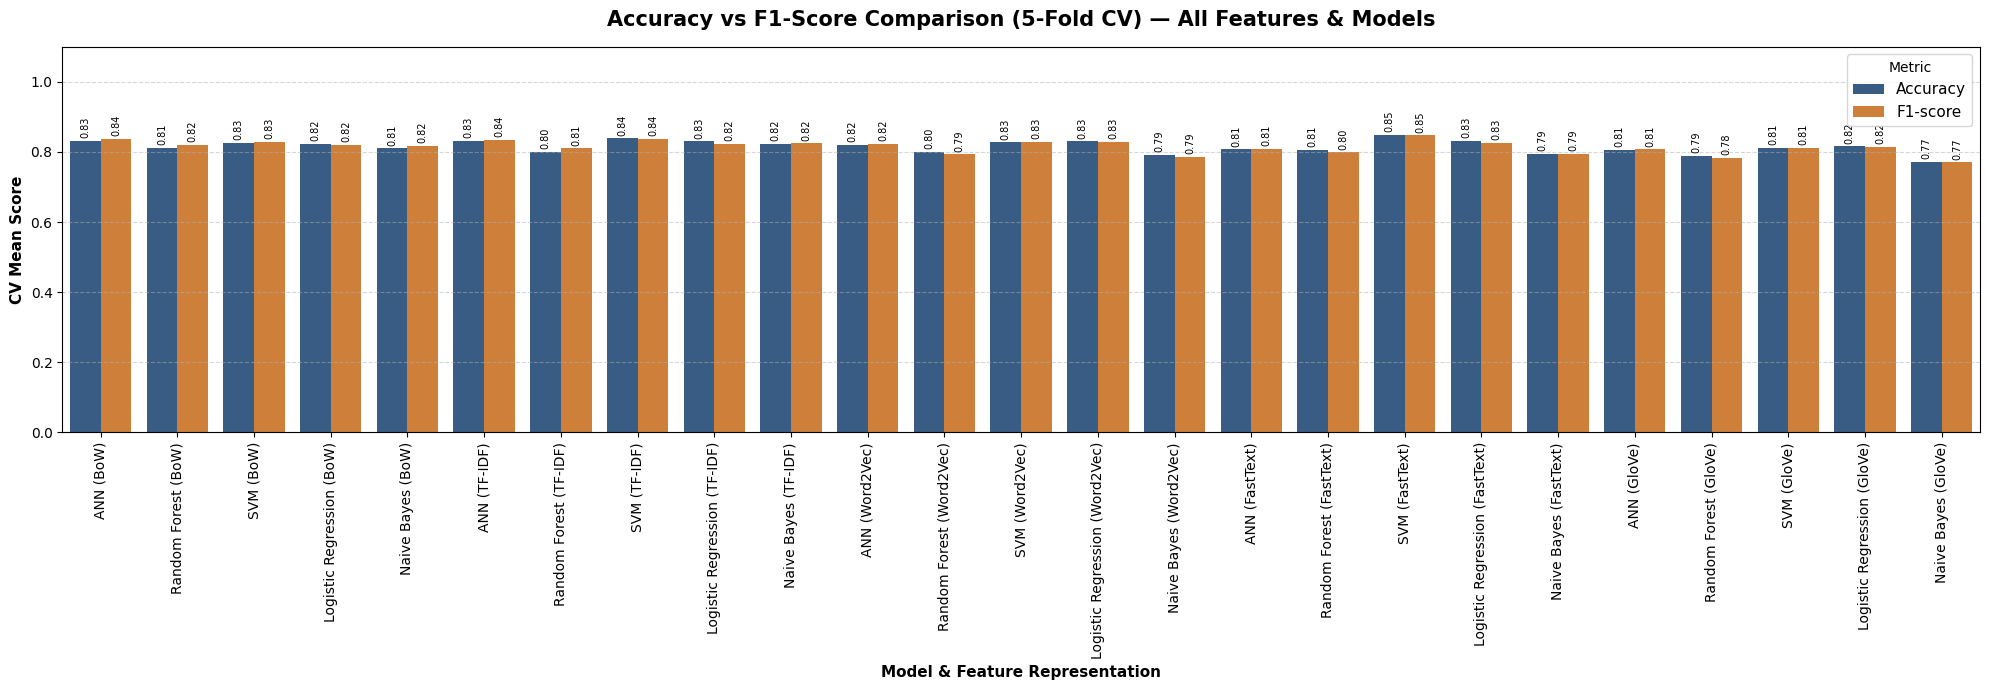

In [52]:
# 2. Transformed ข้อมูลชุด Cross Validation
df_melt_cv = pd.melt(
    df_cv_comparison,
    id_vars=['Feature', 'Model'],
    value_vars=['CV Accuracy', 'CV F1-score'],
    var_name='Metric',
    value_name='Score'
)

# ปรับชื่อให้กระชับใน Legend
df_melt_cv['Metric'] = df_melt_cv['Metric'].replace({'CV Accuracy': 'Accuracy', 'CV F1-score': 'F1-score'})
df_melt_cv['Model_Feature'] = df_melt_cv['Model'] + " (" + df_melt_cv['Feature'] + ")"

plt.figure(figsize=(20, 7))

# สร้าง Bar Plot สำหรับ Cross Validation
ax_cv = sns.barplot(
    data=df_melt_cv,
    x='Model_Feature',
    y='Score',
    hue='Metric',
    palette=['#2b5c8f', '#e67e22']
)

plt.title('Accuracy vs F1-Score Comparison (5-Fold CV) — All Features & Models', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Model & Feature Representation', fontsize=11, fontweight='bold')
plt.ylabel('CV Mean Score', fontsize=11, fontweight='bold')
plt.xticks(rotation=90, fontsize=10)
plt.ylim(0.0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Metric', fontsize=11, loc='upper right')

# ตัวเลขระบุค่าบนยอดแต่ละแท่ง
for p in ax_cv.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax_cv.annotate(f'{height:.2f}',
                       (p.get_x() + p.get_width() / 2., height),
                       ha='center', va='bottom',
                       fontsize=7, color='black',
                       xytext=(0, 2), textcoords='offset points', rotation=90)

plt.tight_layout()
plt.show()

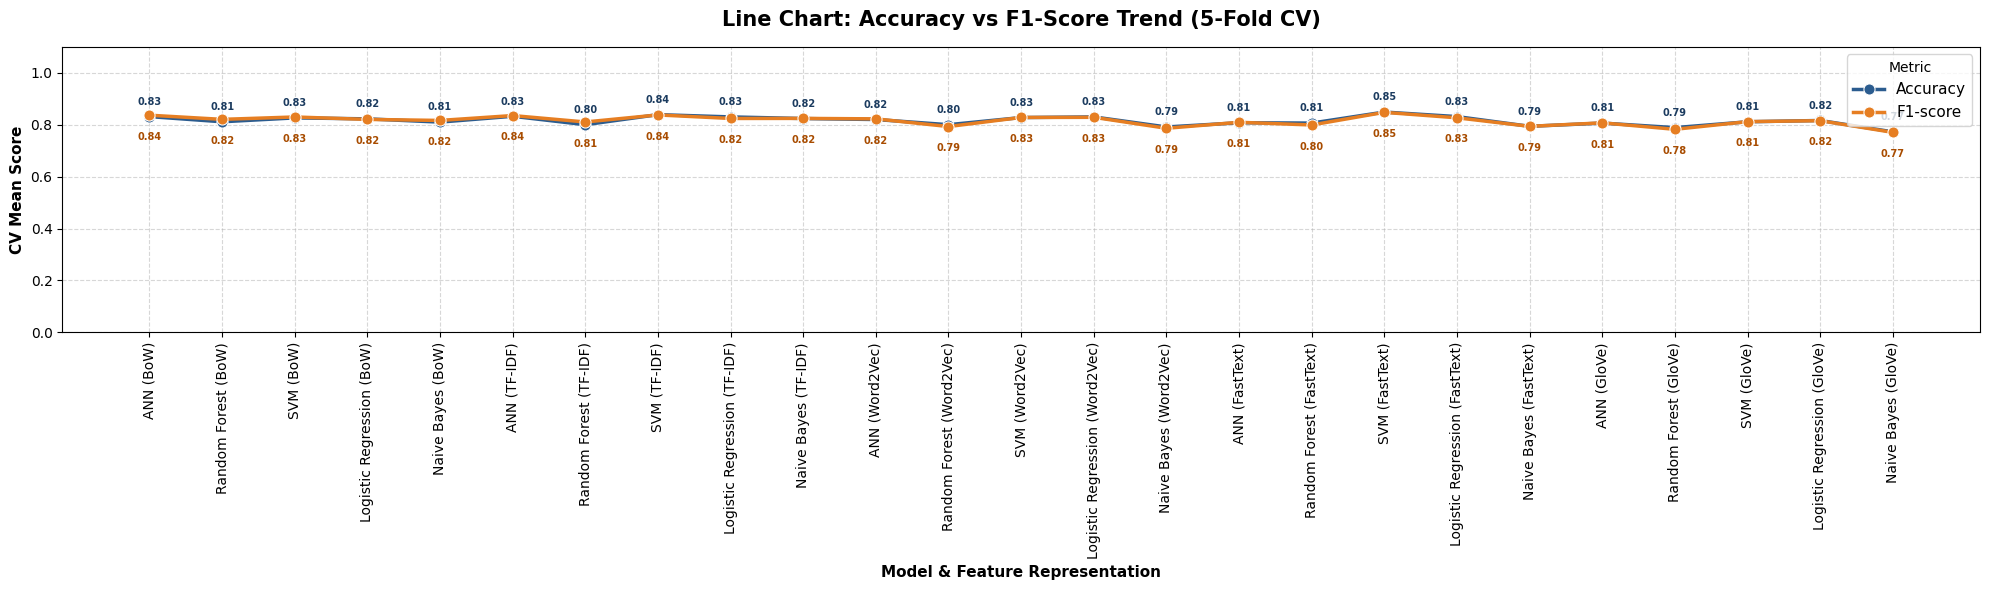

In [53]:
# 1. แปลงข้อมูลชุด 5-Fold CV ด้วย melt
df_melt_cv = pd.melt(
    df_cv_comparison,
    id_vars=['Feature', 'Model'],
    value_vars=['CV Accuracy', 'CV F1-score'],
    var_name='Metric',
    value_name='Score'
)

# เปลี่ยนชื่อ Metric ให้กระชับสำหรับแสดงใน Legend
df_melt_cv['Metric'] = df_melt_cv['Metric'].replace({'CV Accuracy': 'Accuracy', 'CV F1-score': 'F1-score'})
df_melt_cv['Model_Feature'] = df_melt_cv['Model'] + " (" + df_melt_cv['Feature'] + ")"

# --- วาดกราฟเส้นสำหรับ 5-Fold CV ---
plt.figure(figsize=(20, 6))
ax_line = sns.lineplot(
    data=df_melt_cv,
    x='Model_Feature',
    y='Score',
    hue='Metric',
    palette=['#2b5c8f', '#e67e22'],  # สีน้ำเงิน = Accuracy, สีส้ม = F1-Score
    marker='o',
    markersize=8,
    linewidth=2.5,
)

# เติมตัวเลขบนหัวจุด (กำกับค่า Score)
for i in range(len(df_melt_cv)):
    row = df_melt_cv.iloc[i]
    x_val = row['Model_Feature']
    y_val = row['Score']
    metric = row['Metric']

    # Accuracy แสดงไว้ด้านบนจุด, F1-score แสดงไว้ด้านล่างจุด ป้องกันเลขซ้อนทับกัน
    if metric == 'Accuracy':
        y_offset = 7
        va = 'bottom'
        text_color = '#1b3b5f'  # สีน้ำเงินเข้ม
    else:
        y_offset = -12
        va = 'top'
        text_color = '#a84c00'  # สีส้มเข้ม

    ax_line.annotate(
        f'{y_val:.2f}',
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, y_offset),
        ha='center',
        va=va,
        fontsize=7,
        fontweight='bold',
        color=text_color
    )

plt.title(
    'Line Chart: Accuracy vs F1-Score Trend (5-Fold CV)',
    fontsize=15,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Model & Feature Representation', fontsize=11, fontweight='bold')
plt.ylabel('CV Mean Score', fontsize=11, fontweight='bold')
plt.xticks(rotation=90, fontsize=10)
plt.ylim(0.0, 1.1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Metric', fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

**ทดลองทำ Ensemble**

**คัดเลือกโมเดลที่ผ่านเกณฑ์ (Accuracy > 0.8 และ F1 > 0.8)**

In [54]:
# # ==========================================
# # STEP 1: Filter Qualified Models (> 0.8)
# # ==========================================

# threshold = 0.8

# # 1. คัดเลือกโมเดลจาก Split (results_list)
# qualified_split_models = [
#     m for m in results_list
#     if m['acc'] > threshold and m['f1'] > threshold
# ]

# # 2. คัดเลือกโมเดลจาก Cross Validation (cv_results_list)
# qualified_cv_models = [
#     m for m in cv_results_list
#     if m['cv_acc'] > threshold and m['cv_f1'] > threshold
# ]

# # แสดงผลการคัดเลือก
# print("="*60)
# print(f" 1. Qualified Split Models (Acc > {threshold} & F1 > {threshold}): {len(qualified_split_models)} โมเดล")
# print("="*60)
# for i, m in enumerate(qualified_split_models, 1):
#     print(f"  [{i}] {m['name']} | Acc: {m['acc']:.4f} | F1: {m['f1']:.4f}")

# print("\n" + "="*60)
# print(f" 2. Qualified CV Models (CV Acc > {threshold} & CV F1 > {threshold}): {len(qualified_cv_models)} โมเดล")
# print("="*60)
# for i, m in enumerate(qualified_cv_models, 1):
#     print(f"  [{i}] {m['name']} | CV Acc: {m['cv_acc']:.4f} | CV F1: {m['cv_f1']:.4f}")

# # แจ้งเตือนหากโมเดลไม่ถึง 2 ตัว (เพราะ Ensemble ต้องใช้อย่างน้อย 2 โมเดล)
# if len(qualified_split_models) < 2:
#     print("\n⚠️ คำเตือน: โมเดลฝั่ง Split ที่ผ่านเกณฑ์มีน้อยกว่า 2 ตัว อาจต้องปรับ threshold ลงเล็กน้อย")
# if len(qualified_cv_models) < 2:
#     print("\n⚠️ คำเตือน: โมเดลฝั่ง CV ที่ผ่านเกณฑ์มีน้อยกว่า 2 ตัว อาจต้องปรับ threshold ลงเล็กน้อย")

**คัดเลือกโมเดลเเบบเอา TOP ที่ต้องการ**

In [105]:
# ==================================================
# STEP 1 (Option B): Select Top N Best Models
# ==================================================

top_n = 4  # <--- ปรับเปลี่ยนจำนวน Top โมเดลที่ต้องการได้ตรงนี้ (เช่น 3, 5, 10)

# 1. เรียงลำดับและคัดเลือก Top N โมเดลจาก Split (เรียงจาก F1-score และ Acc มากไปน้อย)
qualified_split_models = sorted(
    results_list,
    key=lambda x: (x['f1'], x['acc']),
    reverse=True
)[:top_n]

# 2. เรียงลำดับและคัดเลือก Top N โมเดลจาก Cross Validation
qualified_cv_models = sorted(
    cv_results_list,
    key=lambda x: (x['cv_f1'], x['cv_acc']),
    reverse=True
)[:top_n]

# แสดงผลการคัดเลือก
print("=" * 60)
print(f" 1. Top {len(qualified_split_models)} Qualified Split Models")
print("=" * 60)
for i, m in enumerate(qualified_split_models, 1):
    print(f"[{i}] {m['name']} | Acc: {m['acc']:.4f} | F1: {m['f1']:.4f}")

print("\n" + "=" * 60)
print(f" 2. Top {len(qualified_cv_models)} Qualified CV Models")
print("=" * 60)
for i, m in enumerate(qualified_cv_models, 1):
    print(f"[{i}] {m['name']} | CV Acc: {m['cv_acc']:.4f} | CV F1: {m['cv_f1']:.4f}")

 1. Top 4 Qualified Split Models
[1] BoW + ANN | Acc: 0.8300 | F1: 0.8365
[2] FastText + ANN | Acc: 0.8300 | F1: 0.8333
[3] TF-IDF + ANN | Acc: 0.8050 | F1: 0.8134
[4] BoW + Random Forest | Acc: 0.7950 | F1: 0.8093

 2. Top 4 Qualified CV Models
[1] FastText + SVM | CV Acc: 0.8488 | CV F1: 0.8476
[2] TF-IDF + SVM | CV Acc: 0.8387 | CV F1: 0.8376
[3] BoW + ANN | CV Acc: 0.8313 | CV F1: 0.8366
[4] TF-IDF + ANN | CV Acc: 0.8325 | CV F1: 0.8352


**Voting Ensemble (ทั้ง Hard Voting และ Soft Voting)**

Hard Voting (เสียงข้างมาก): ให้ทุกโมเดลทายคำตอบออกมาเป็น 0 หรือ 1 แล้วโหวตเอาตัวเลือกที่ได้เสียงส่วนใหญ่

Soft Voting (เฉลี่ยความน่าจะเป็น): นำค่าความน่าจะเป็น (predict_proba) จากทุกโมเดลมารวมแล้วหาค่าเฉลี่ย คลาสไหนได้ความน่าจะเป็นเฉลี่ยสูงสุดจะถูกเลือกเป็นคำตอบ (มักให้ผลลัพธ์ดีกว่า Hard Voting)

In [106]:
# ==========================================
# STEP 2: Voting Ensemble (Hard & Soft)
# ==========================================


# 1. สร้าง List สำหรับเก็บผลลัพธ์ทั้งหมดไว้ตั้งแต่ต้น
ensemble_results = []

# ฟังก์ชันสำหรับประเมินผลและแสดงค่าแบบกะทัดรัด
def evaluate_ensemble(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    print(f"[{name}]\n  -> Acc: {acc:.5f} | Precision: {prec:.5f} | Recall: {rec:.4f} | F1: {f1:.6f}\n")
    return {"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

# ฟังก์ชันช่วยดึง Probability (รองรับโมเดลที่ไม่มี predict_proba เช่น LinearSVC)
def get_model_probabilities(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)
    elif hasattr(model, "decision_function"):
        # แปลง decision_function (distance to hyperplane) เป็นความน่าจะเป็นแบบคร่าวๆ ด้วย Sigmoid function
        decision = model.decision_function(X)
        # กรณี Binary Classification decision จะมีมิติเดียว
        if len(decision.shape) == 1 or decision.ndim == 1:
            probs_pos = 1 / (1 + np.exp(-decision))
            return np.column_stack((1 - probs_pos, probs_pos))
        else:
            exp_dec = np.exp(decision)
            return exp_dec / np.sum(exp_dec, axis=1, keepdims=True)
    else:
        # กรณีแย่ที่สุด: แปลงจากผลการ Predict (Hard prediction) เป็น One-hot representation
        preds = model.predict(X)
        return np.column_stack((1 - preds, preds))

# Map เพื่อดึง X_test ตาม Feature Name สำหรับฝั่ง CV
feature_xtest_map = {feat_name: X_te for feat_name, (X_tr, X_te) in feature_sets.items()}

print("="*65)
print(" PART 1: VOTING ENSEMBLE - TRAIN-TEST SPLIT MODELS")
print("="*65)

# --- 1.1 Hard Voting (Split) ---
preds_split_list = [m['model'].predict(m['X_test']) for m in qualified_split_models]
# คำนวณเสียงข้างมาก (ค่าเฉลี่ยของการทำนาย >= 0.5 คือ 1)
hard_split_pred = (np.mean(preds_split_list, axis=0) >= 0.5).astype(int)
res_split_hard = evaluate_ensemble(y_test, hard_split_pred, "Split - Hard Voting")
ensemble_results.append(res_split_hard)

# --- 1.2 Soft Voting (Split) ---
probs_split_list = [get_model_probabilities(m['model'], m['X_test']) for m in qualified_split_models]
avg_probs_split = np.mean(probs_split_list, axis=0)
soft_split_pred = np.argmax(avg_probs_split, axis=1)
res_split_soft = evaluate_ensemble(y_test, soft_split_pred, "Split - Soft Voting")
ensemble_results.append(res_split_soft)


print("="*65)
print(" PART 2: VOTING ENSEMBLE - CROSS-VALIDATION MODELS")
print("="*65)

# --- 2.1 Hard Voting (CV) ---
preds_cv_list = []
for m in qualified_cv_models:
    X_te = feature_xtest_map[m['feature']]
    for est in m['estimators']: # ทำนายผ่านทั้ง 5 Fold Estimators
        preds_cv_list.append(est.predict(X_te))

hard_cv_pred = (np.mean(preds_cv_list, axis=0) >= 0.5).astype(int)
res_cv_hard = evaluate_ensemble(y_test, hard_cv_pred, "CV - Hard Voting")
ensemble_results.append(res_cv_hard)

# --- 2.2 Soft Voting (CV) ---
probs_cv_list = []
for m in qualified_cv_models:
    X_te = feature_xtest_map[m['feature']]
    for est in m['estimators']:
        probs_cv_list.append(get_model_probabilities(est, X_te))

avg_probs_cv = np.mean(probs_cv_list, axis=0)
soft_cv_pred = np.argmax(avg_probs_cv, axis=1)
res_cv_soft = evaluate_ensemble(y_test, soft_cv_pred, "CV - Soft Voting")
ensemble_results.append(res_cv_soft)

# 2. แปลงรายการผลลัพธ์ทั้งหมดใน ensemble_results เป็น DataFrame
df_ensemble = pd.DataFrame(ensemble_results)
display(df_ensemble)

 PART 1: VOTING ENSEMBLE - TRAIN-TEST SPLIT MODELS
[Split - Hard Voting]
  -> Acc: 0.85000 | Precision: 0.79167 | Recall: 0.9500 | F1: 0.863636

[Split - Soft Voting]
  -> Acc: 0.83000 | Precision: 0.81731 | Recall: 0.8500 | F1: 0.833333

 PART 2: VOTING ENSEMBLE - CROSS-VALIDATION MODELS
[CV - Hard Voting]
  -> Acc: 0.81500 | Precision: 0.81818 | Recall: 0.8100 | F1: 0.814070

[CV - Soft Voting]
  -> Acc: 0.79000 | Precision: 0.79000 | Recall: 0.7900 | F1: 0.790000



,Model,Accuracy,Precision,Recall,F1-score
0,Split - Hard Voting,0.850,0.791667,0.95,0.863636
1,Split - Soft Voting,0.830,0.817308,0.85,0.833333
2,CV - Hard Voting,0.815,0.818182,0.81,0.814070
3,CV - Soft Voting,0.790,0.790000,0.79,0.790000


**Weighted Ensemble (ถ่วงน้ำหนักตามความเก่งของโมเดล)**

การถ่วงน้ำหนัก (Weighted Average): ใน Soft Voting ปกติ ทุกโมเดลจะมีเสียงเท่ากันทั้งหมด (น้ำหนักเท่ากับ 1) แต่ใน Weighted Ensemble เราจะนำค่า F1-score ของแต่ละโมเดลมาแปลงเป็น น้ำหนัก (Weight)

โมเดลไหนแม่นยำกว่า จะมีสิทธิ์โหวตเสียงดังกว่า: โมเดลที่มี F1-score สูงกว่าจะได้น้ำหนักในการคูณกับค่า ความน่าจะเป็นมากกว่า ทำให้คำตอบเอนเอียงไปทางโมเดลที่เก่งที่สุด

In [107]:
# ==========================================
# STEP 3: Weighted Ensemble (ถ่วงน้ำหนักตามประสิทธิภาพโมเดล)
# ==========================================
import numpy as np
import pandas as pd

print("="*65)
print(" PART 1: WEIGHTED ENSEMBLE - TRAIN-TEST SPLIT MODELS")
print("="*65)

# --- 1.1 คำนวณ Weight จาก F1-score (Split) ---
split_f1_scores = np.array([m['f1'] for m in qualified_split_models])
# Normalize ค่าน้ำหนักให้ผลรวมเท่ากับ 1.0
split_weights = split_f1_scores / np.sum(split_f1_scores)

print("น้ำหนักของแต่ละโมเดล (Split):")
for m, w in zip(qualified_split_models, split_weights):
    print(f"  - {m['name']} | F1: {m['f1']:.4f} -> Weight: {w:.4f}")

# คำนวณ Weighted Probability
weighted_probs_split = np.zeros_like(get_model_probabilities(qualified_split_models[0]['model'], qualified_split_models[0]['X_test']))
for m, w in zip(qualified_split_models, split_weights):
    probs = get_model_probabilities(m['model'], m['X_test'])
    weighted_probs_split += w * probs

# ทำนายคลาสสุดท้าย
weighted_split_pred = np.argmax(weighted_probs_split, axis=1)
print("\nผลลัพธ์:")
res_split_weighted = evaluate_ensemble(y_test, weighted_split_pred, "Split - Weighted Ensemble")
ensemble_results.append(res_split_weighted)  # บันทึกผลลัพธ์ Split Weighted


print("="*65)
print(" PART 2: WEIGHTED ENSEMBLE - CROSS-VALIDATION MODELS")
print("="*65)

# --- 2.1 คำนวณ Weight จาก CV F1-score ---
cv_f1_scores = np.array([m['cv_f1'] for m in qualified_cv_models])
cv_weights = cv_f1_scores / np.sum(cv_f1_scores)

print("น้ำหนักของแต่ละโมเดล (CV):")
for m, w in zip(qualified_cv_models, cv_weights):
    print(f"  - {m['name']} | CV F1: {m['cv_f1']:.4f} -> Weight: {w:.4f}")

weighted_probs_cv = None
for m, w in zip(qualified_cv_models, cv_weights):
    X_te = feature_xtest_map[m['feature']]
    # เฉลี่ย Probability ของทั้ง 5 Fold ของโมเดลนี้ก่อน
    fold_probs = np.mean([get_model_probabilities(est, X_te) for est in m['estimators']], axis=0)

    if weighted_probs_cv is None:
        weighted_probs_cv = np.zeros_like(fold_probs)

    weighted_probs_cv += w * fold_probs

# ทำนายคลาสสุดท้าย
weighted_cv_pred = np.argmax(weighted_probs_cv, axis=1)
print("\nผลลัพธ์:")
res_cv_weighted = evaluate_ensemble(y_test, weighted_cv_pred, "CV - Weighted Ensemble")
ensemble_results.append(res_cv_weighted)  # บันทึกผลลัพธ์ CV Weighted

# ------------------------------------------
# แสดงผลการประเมินรวมทั้งหมดสะสมจาก STEP 2 และ STEP 3
# ------------------------------------------
df_ensemble = pd.DataFrame(ensemble_results)
display(df_ensemble)

 PART 1: WEIGHTED ENSEMBLE - TRAIN-TEST SPLIT MODELS
น้ำหนักของแต่ละโมเดล (Split):
  - BoW + ANN | F1: 0.8365 -> Weight: 0.2541
  - FastText + ANN | F1: 0.8333 -> Weight: 0.2531
  - TF-IDF + ANN | F1: 0.8134 -> Weight: 0.2470
  - BoW + Random Forest | F1: 0.8093 -> Weight: 0.2458

ผลลัพธ์:
[Split - Weighted Ensemble]
  -> Acc: 0.83500 | Precision: 0.82524 | Recall: 0.8500 | F1: 0.837438

 PART 2: WEIGHTED ENSEMBLE - CROSS-VALIDATION MODELS
น้ำหนักของแต่ละโมเดล (CV):
  - FastText + SVM | CV F1: 0.8476 -> Weight: 0.2525
  - TF-IDF + SVM | CV F1: 0.8376 -> Weight: 0.2495
  - BoW + ANN | CV F1: 0.8366 -> Weight: 0.2492
  - TF-IDF + ANN | CV F1: 0.8352 -> Weight: 0.2488

ผลลัพธ์:
[CV - Weighted Ensemble]
  -> Acc: 0.79000 | Precision: 0.79000 | Recall: 0.7900 | F1: 0.790000



,Model,Accuracy,Precision,Recall,F1-score
0,Split - Hard Voting,0.850,0.791667,0.95,0.863636
1,Split - Soft Voting,0.830,0.817308,0.85,0.833333
2,CV - Hard Voting,0.815,0.818182,0.81,0.814070
3,CV - Soft Voting,0.790,0.790000,0.79,0.790000
4,Split - Weighted Ensemble,0.835,0.825243,0.85,0.837438
5,CV - Weighted Ensemble,0.790,0.790000,0.79,0.790000


**Stacking Ensemble (Meta-Learner)**

หลักการทำงาน (Level-0 & Level-1):

Level-0 (Base Models): ใช้โมเดลที่ผ่านเกณฑ์ที่เราคัดเลือกไว้ ทำนายผลออกมาเป็นค่าความน่าจะเป็น (predict_proba)

Level-1 (Meta-Learner): นำค่าความน่าจะเป็นที่ทายได้จากทุก Base Model มารวมกันสร้างเป็น Dataset ชุดใหม่ (Meta-Features) แล้วให้โมเดลตัวใหม่ที่เป็น Meta-Learner (เช่น LogisticRegression หรือ GradientBoostingClassifier) เรียนรู้เพื่อตัดสินใจเป็นคำตอบสุดท้าย

ทำไมถึงทรงพลัง: Meta-Learner จะเรียนรู้เองว่าโมเดลไหนเก่งในสถานการณ์ใด และควรเชื่อคำตอบของโมเดลไหนมากกว่ากัน



In [108]:
# ==========================================
# STEP 4: Stacking Ensemble (Meta-Learner)
# ==========================================
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

# Map เพื่อดึง X_train ตาม Feature Name
feature_xtrain_map = {feat_name: X_tr for feat_name, (X_tr, X_te) in feature_sets.items()}

# ---------------------------------------------------------
# ฟังก์ชันสร้าง Meta-Features (ค่า Probability จาก Base Models)
# ---------------------------------------------------------
def create_meta_features_split(models):
    train_meta, test_meta = [], []
    for m in models:
        feat_name = m['name'].split(' + ')[0]
        X_tr = feature_xtrain_map[feat_name]
        X_te = m['X_test']

        # ใช้ get_model_probabilities ที่นิยามไว้ในขั้นตอนก่อนหน้า
        p_tr = get_model_probabilities(m['model'], X_tr)[:, 1]
        p_te = get_model_probabilities(m['model'], X_te)[:, 1]

        train_meta.append(p_tr)
        test_meta.append(p_te)

    return np.column_stack(train_meta), np.column_stack(test_meta)

def create_meta_features_cv(cv_models):
    train_meta, test_meta = [], []
    for m in cv_models:
        feat_name = m['feature']
        X_tr = feature_xtrain_map[feat_name]
        X_te = feature_xtest_map[feat_name]

        p_tr_fold = np.mean([get_model_probabilities(est, X_tr)[:, 1] for est in m['estimators']], axis=0)
        p_te_fold = np.mean([get_model_probabilities(est, X_te)[:, 1] for est in m['estimators']], axis=0)

        train_meta.append(p_tr_fold)
        test_meta.append(p_te_fold)

    return np.column_stack(train_meta), np.column_stack(test_meta)


print("="*65)
print(" PART 1: STACKING ENSEMBLE - TRAIN-TEST SPLIT MODELS")
print("="*65)

# 1. สร้าง Meta-Features สำหรับ Split
X_meta_train_split, X_meta_test_split = create_meta_features_split(qualified_split_models)

# 1.1 Meta-Learner: Logistic Regression
meta_lr_split = LogisticRegression(random_state=42)
meta_lr_split.fit(X_meta_train_split, y_train)
pred_lr_split = meta_lr_split.predict(X_meta_test_split)
res_split_stack_lr = evaluate_ensemble(y_test, pred_lr_split, "Split Stacking - Meta-Learner (Logistic Regression)")
ensemble_results.append(res_split_stack_lr)  # บันทึกผลลัพธ์ Split Stacking (LR)

# 1.2 Meta-Learner: Gradient Boosting
meta_gb_split = GradientBoostingClassifier(n_estimators=50, random_state=42)
meta_gb_split.fit(X_meta_train_split, y_train)
pred_gb_split = meta_gb_split.predict(X_meta_test_split)
res_split_stack_gb = evaluate_ensemble(y_test, pred_gb_split, "Split Stacking - Meta-Learner (Gradient Boosting)")
ensemble_results.append(res_split_stack_gb)  # บันทึกผลลัพธ์ Split Stacking (GB)


print("="*65)
print(" PART 2: STACKING ENSEMBLE - CROSS-VALIDATION MODELS")
print("="*65)

# 2. สร้าง Meta-Features สำหรับ CV
X_meta_train_cv, X_meta_test_cv = create_meta_features_cv(qualified_cv_models)

# 2.1 Meta-Learner: Logistic Regression
meta_lr_cv = LogisticRegression(random_state=42)
meta_lr_cv.fit(X_meta_train_cv, y_train)
pred_lr_cv = meta_lr_cv.predict(X_meta_test_cv)
res_cv_stack_lr = evaluate_ensemble(y_test, pred_lr_cv, "CV Stacking - Meta-Learner (Logistic Regression)")
ensemble_results.append(res_cv_stack_lr)  # บันทึกผลลัพธ์ CV Stacking (LR)

# 2.2 Meta-Learner: Gradient Boosting
meta_gb_cv = GradientBoostingClassifier(n_estimators=50, random_state=42)
meta_gb_cv.fit(X_meta_train_cv, y_train)
pred_gb_cv = meta_gb_cv.predict(X_meta_test_cv)
res_cv_stack_gb = evaluate_ensemble(y_test, pred_gb_cv, "CV Stacking - Meta-Learner (Gradient Boosting)")
ensemble_results.append(res_cv_stack_gb)  # บันทึกผลลัพธ์ CV Stacking (GB)

# ---------------------------------------------------------
# แสดงผลการประเมินรวมทั้งหมด (Voting + Weighted + Stacking)
# ---------------------------------------------------------
df_ensemble = pd.DataFrame(ensemble_results)
display(df_ensemble)

 PART 1: STACKING ENSEMBLE - TRAIN-TEST SPLIT MODELS
[Split Stacking - Meta-Learner (Logistic Regression)]
  -> Acc: 0.83500 | Precision: 0.82524 | Recall: 0.8500 | F1: 0.837438

[Split Stacking - Meta-Learner (Gradient Boosting)]
  -> Acc: 0.82500 | Precision: 0.81553 | Recall: 0.8400 | F1: 0.827586

 PART 2: STACKING ENSEMBLE - CROSS-VALIDATION MODELS
[CV Stacking - Meta-Learner (Logistic Regression)]
  -> Acc: 0.78500 | Precision: 0.77670 | Recall: 0.8000 | F1: 0.788177

[CV Stacking - Meta-Learner (Gradient Boosting)]
  -> Acc: 0.81500 | Precision: 0.77876 | Recall: 0.8800 | F1: 0.826291



,Model,Accuracy,Precision,Recall,F1-score
0,Split - Hard Voting,0.850,0.791667,0.95,0.863636
1,Split - Soft Voting,0.830,0.817308,0.85,0.833333
2,CV - Hard Voting,0.815,0.818182,0.81,0.814070
3,CV - Soft Voting,0.790,0.790000,0.79,0.790000
4,Split - Weighted Ensemble,0.835,0.825243,0.85,0.837438
5,CV - Weighted Ensemble,0.790,0.790000,0.79,0.790000
6,Split Stacking - Meta-Learner (Logistic Regres...,0.835,0.825243,0.85,0.837438
7,Split Stacking - Meta-Learner (Gradient Boosting),0.825,0.815534,0.84,0.827586
8,CV Stacking - Meta-Learner (Logistic Regression),0.785,0.776699,0.80,0.788177
9,CV Stacking - Meta-Learner (Gradient Boosting),0.815,0.778761,0.88,0.826291


ตารางสรุปผลลัพธ์ Ensemble:


,Model,Accuracy,Precision,Recall,F1-score
0,Split - Hard Voting,0.850,0.791667,0.95,0.863636
1,Split - Weighted Ensemble,0.835,0.825243,0.85,0.837438
2,Split Stacking - Meta-Learner (Logistic Regres...,0.835,0.825243,0.85,0.837438
3,Split - Soft Voting,0.830,0.817308,0.85,0.833333
4,Split Stacking - Meta-Learner (Gradient Boosting),0.825,0.815534,0.84,0.827586
5,CV - Hard Voting,0.815,0.818182,0.81,0.814070
6,CV Stacking - Meta-Learner (Gradient Boosting),0.815,0.778761,0.88,0.826291
7,CV - Soft Voting,0.790,0.790000,0.79,0.790000
8,CV - Weighted Ensemble,0.790,0.790000,0.79,0.790000
9,CV Stacking - Meta-Learner (Logistic Regression),0.785,0.776699,0.80,0.788177


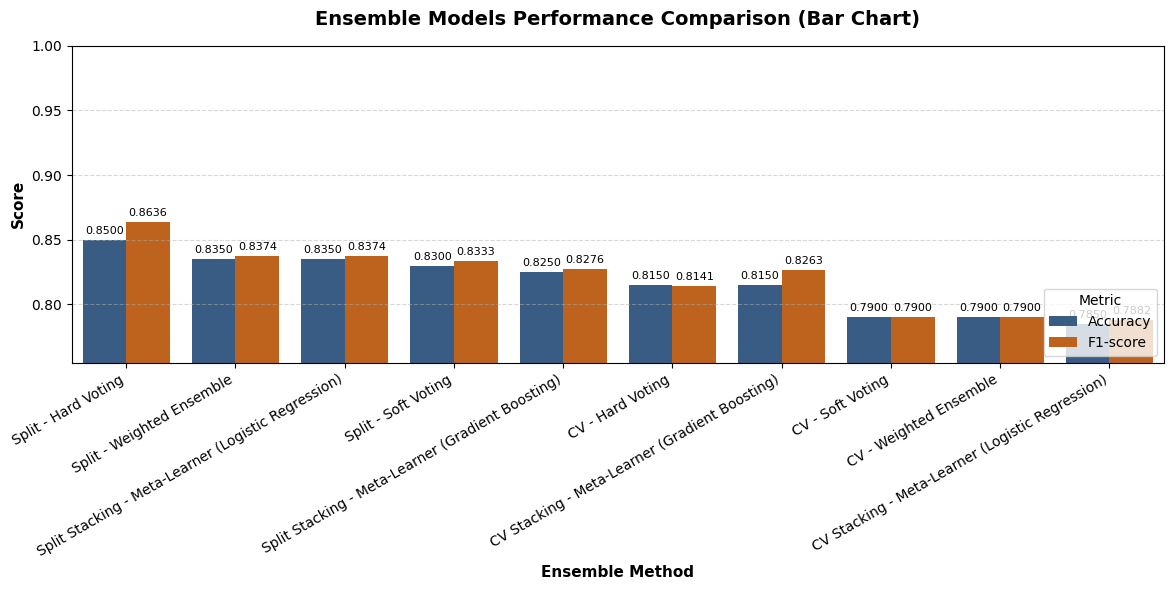

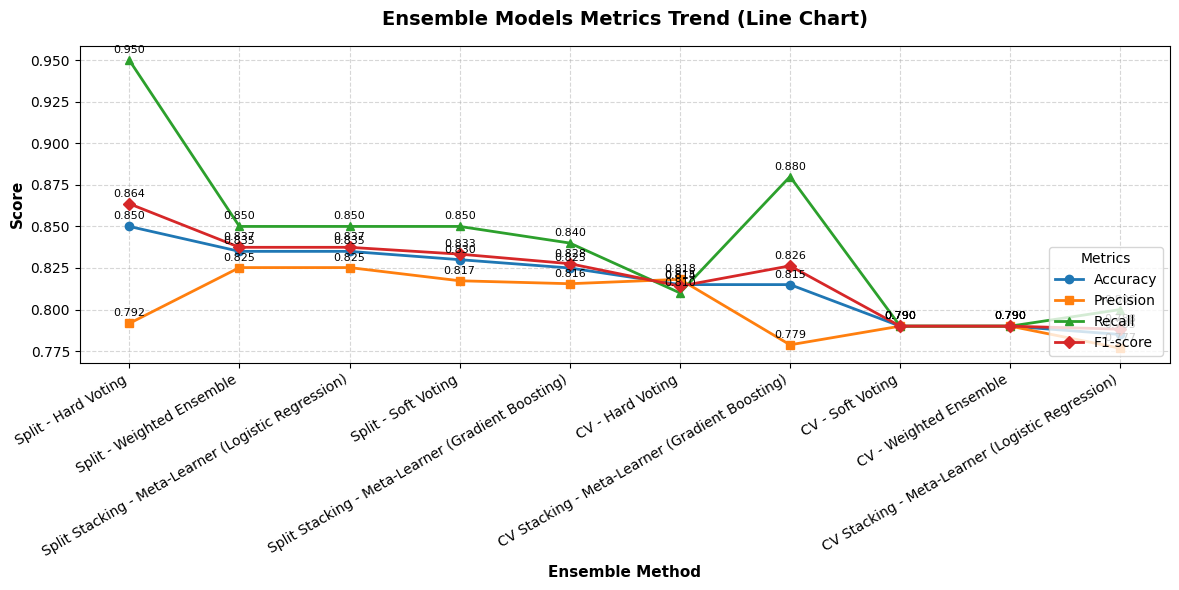

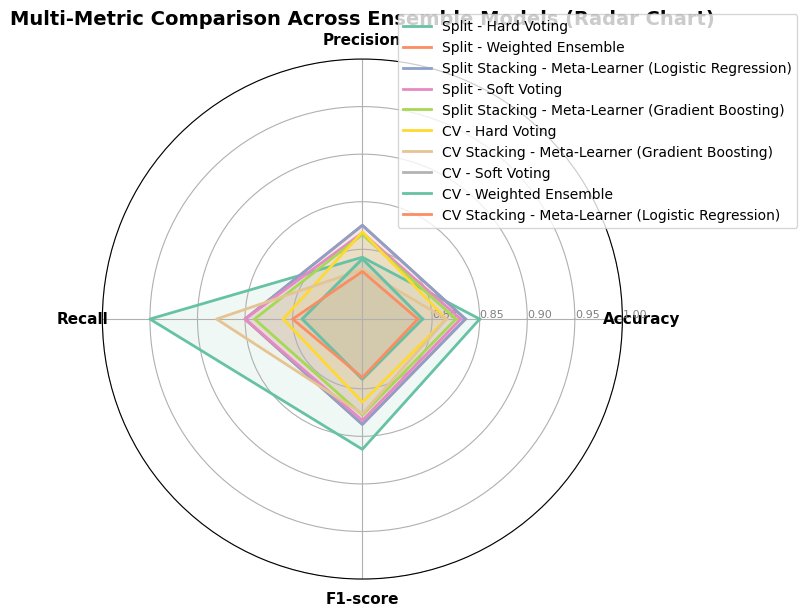

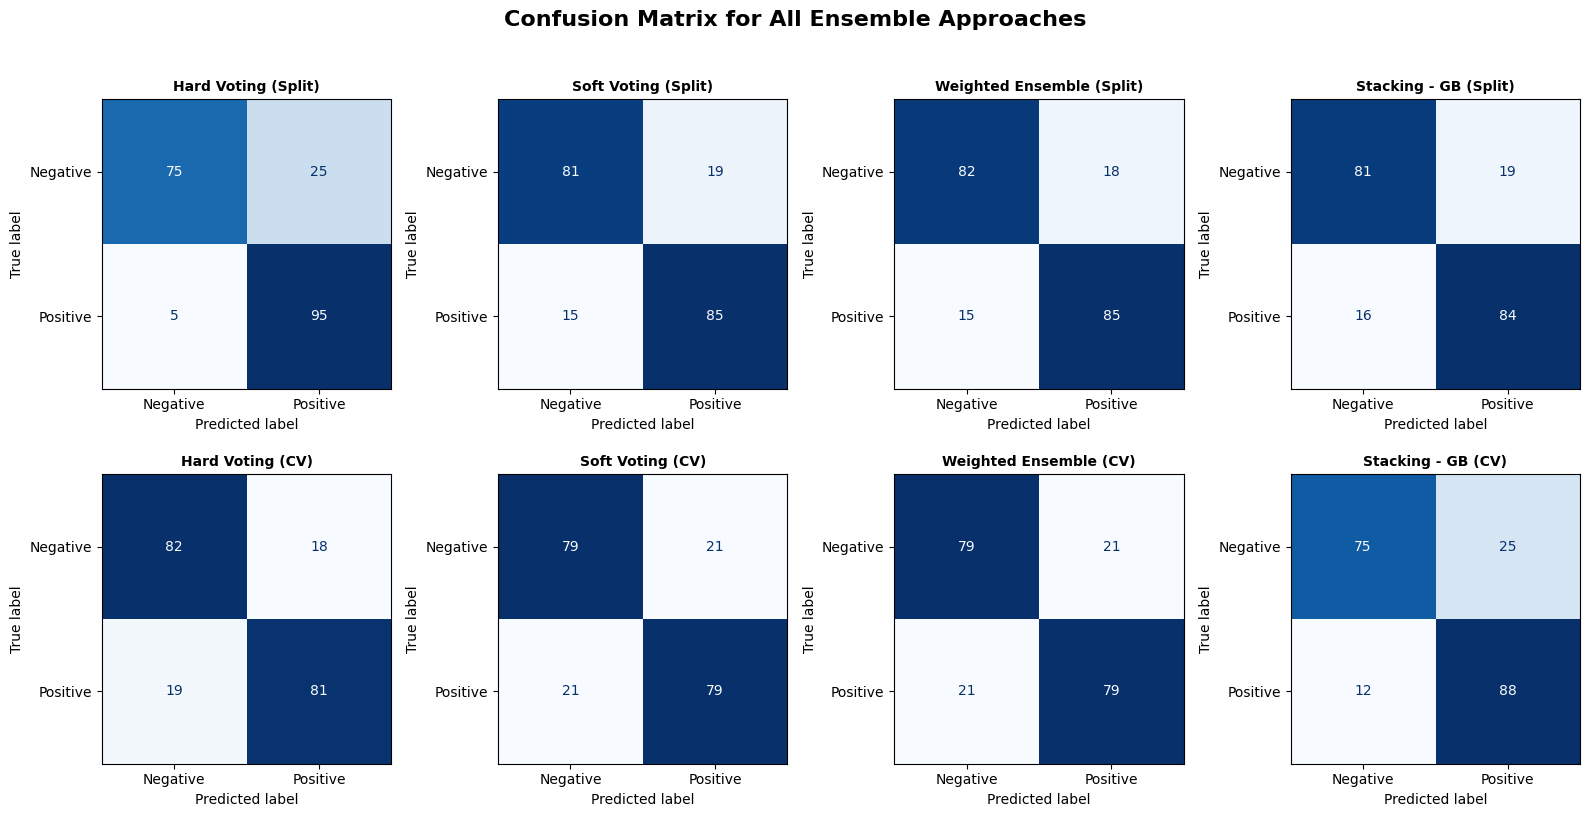

In [109]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ==================================================
# 0. เตรียมข้อมูล DataFrame และปรับเปลี่ยนชื่อคอลัมน์ให้อยู่ในมาตรฐานเดียวกัน
# ==================================================
df_ensemble = pd.DataFrame(ensemble_results)

# Map ชื่อคอลัมน์เผื่อกรณีที่มีทั้งเวอร์ชันตัวเต็ม/ย่อ
column_mapping = {'name': 'Model', 'acc': 'Accuracy', 'prec': 'Precision', 'rec': 'Recall', 'f1': 'F1-score'}
df_ensemble = df_ensemble.rename(columns=column_mapping)

#เอาไว้เรียง acc จากมากไปน้อย
#df_ensemble = df_ensemble.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

print("ตารางสรุปผลลัพธ์ Ensemble:")
display(df_ensemble)


# ==================================================
# 1. กราฟแท่ง (Bar Chart) - เปรียบเทียบ Accuracy และ F1-score
# ==================================================
df_melted_bar = pd.melt(
    df_ensemble,
    id_vars=['Model'],
    value_vars=['Accuracy', 'F1-score'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))
ax1 = sns.barplot(
    data=df_melted_bar,
    x='Model',
    y='Score',
    hue='Metric',
    palette=['#2b5c8f', '#d95f02']
)

plt.title('Ensemble Models Performance Comparison (Bar Chart)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ensemble Method', fontsize=11, fontweight='bold')
plt.ylabel('Score', fontsize=11, fontweight='bold')
plt.xticks(rotation=30, ha='right')

# ปรับแกน Y ให้เห็นความต่างชัดเจน
min_score = df_melted_bar['Score'].min()
plt.ylim(max(0, min_score - 0.03), 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Metric', loc='lower right', frameon=True)

# ตัวเลขกำกับยอดแท่งกราฟ
for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.4f}',
                     (p.get_x() + p.get_width() / 2.0, height),
                     ha='center', va='bottom', fontsize=8,
                     xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


# ==================================================
# 2. กราฟเส้น (Line Chart) - ดูแนวโน้มประสิทธิภาพของแต่ละวิธี
# ==================================================
plt.figure(figsize=(12, 6))
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-score']
markers = ['o', 's', '^', 'D']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for metric, marker, color in zip(metrics_to_plot, markers, colors):
    if metric in df_ensemble.columns:
        plt.plot(df_ensemble['Model'], df_ensemble[metric], marker=marker, linewidth=2, label=metric, color=color)

plt.title('Ensemble Models Metrics Trend (Line Chart)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ensemble Method', fontsize=11, fontweight='bold')
plt.ylabel('Score', fontsize=11, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Metrics', loc='lower right', frameon=True)

# แสดงค่าตัวเลขกำกับจุดบนกราฟเส้น
for metric in metrics_to_plot:
    if metric in df_ensemble.columns:
        for x, y in enumerate(df_ensemble[metric]):
            plt.annotate(f'{y:.3f}', (x, y), textcoords="offset points", xytext=(0, 5), ha='center', fontsize=8)

plt.tight_layout()
plt.show()


# ==================================================
# 3. กราฟเรดาร์ (Radar Chart / Spider Plot)
# ==================================================
categories = ['Accuracy', 'Precision', 'Recall', 'F1-score']
N = len(categories)

# คำนวณมุมสำหรับแต่ละแกน
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1] # ปิดวงกลม

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# ตั้งค่าแกน Radar
plt.xticks(angles[:-1], categories, size=11, fontweight='bold')
ax.set_rlabel_position(0)

# กำหนดช่วงแกนความสูง (0.7 - 1.0)
radar_min = min([df_ensemble[c].min() for c in categories if c in df_ensemble.columns])
plt.yticks([0.8, 0.85, 0.9, 0.95, 1.0], ["0.80", "0.85", "0.90", "0.95", "1.00"], color="grey", size=8)
plt.ylim(max(0, radar_min - 0.05), 1.0)

# พล็อตเส้นเรดาร์ของแต่ละ Ensemble Model
palette = sns.color_palette("Set2", len(df_ensemble))
for idx, row in df_ensemble.iterrows():
    values = [row[cat] for cat in categories]
    values += values[:1] # ปิดวงกลม
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=row['Model'], color=palette[idx])
    ax.fill(angles, values, color=palette[idx], alpha=0.1)

plt.title('Multi-Metric Comparison Across Ensemble Models (Radar Chart)', size=14, fontweight='bold', pad=25)
plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), frameon=True)
plt.tight_layout()
plt.show()


# ==================================================
# 4. คอนฟิวชันแมตริกซ์ (Confusion Matrix)
# ==================================================
# รวบรวม Predictions ของแต่ละโมเดลมาเปรียบเทียบ
dict_predictions = {
    'Hard Voting (Split)': hard_split_pred,
    'Soft Voting (Split)': soft_split_pred,
    'Weighted Ensemble (Split)': weighted_split_pred,
    'Stacking - GB (Split)': pred_gb_split,
    'Hard Voting (CV)': hard_cv_pred,
    'Soft Voting (CV)': soft_cv_pred,
    'Weighted Ensemble (CV)': weighted_cv_pred,
    'Stacking - GB (CV)': pred_gb_cv
}

# สร้าง Subplots สำหรับแสดง Confusion Matrix หลายๆ โมเดลพร้อมกัน
num_models = len(dict_predictions)
cols = 4
rows = (num_models + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten()

for idx, (name, y_pred) in enumerate(dict_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(name, fontsize=10, fontweight='bold')
    axes[idx].grid(False)

# ซ่อน Subplots ที่ไม่ได้ใช้งาน
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Confusion Matrix for All Ensemble Approaches', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()